# SegFormer-B2 vs U-Net (ResNet-50) on LoveDA — Google Colab (T4) edition

Standalone notebook: it installs its own dependencies, downloads LoveDA, trains/evaluates both models and builds the result
tables and figures. Generated from the `dl_research` package by `scripts/build_notebook.py`.

**Before you start**
1. *Runtime → Change runtime type → T4 GPU.*
2. Run all cells top to bottom (the first cells install packages and mount Google Drive).
3. Outputs (checkpoints, metrics, figures) are written to **Google Drive** (`MyDrive/segformer_vs_unet/`), so a disconnect does not
   lose finished work. After a disconnect: reconnect and *Run all* again. Finished runs are skipped; an interrupted run resumes from
   its last checkpoint (saved at each validation epoch).

**What gets downloaded (only when you run the cells):** Python packages from PyPI; the LoveDA `Train.zip` (4.0 GB) and `Val.zip`
(2.4 GB) from Zenodo, checksum-verified (`Test.zip` has no labels and is skipped); ImageNet-pretrained weights for ResNet-50
(via `segmentation_models_pytorch`) and `nvidia/mit-b2` (Hugging Face Hub). LoveDA is for non-commercial academic use (the Zenodo
record's description states CC BY-NC-SA 4.0; its metadata says CC-BY-4.0, so read the terms yourself).

**Experiments:** section 6 = Experiment 1 (SegFormer-B2 vs U-Net, full training set), section 7 = Experiment 2 (10% / 25% / 100% of the labels), section 8 = Experiment 3 (urban vs rural and per-class results, from the stored validation metrics).

**No results are claimed.** Hypotheses are plans, not findings. Everything is reported on the **validation** split (test labels
are not public), which is also used for LR tuning and checkpoint selection, so numbers are optimistically biased.

**Time:** the full study is long (many GPU-hours). Cell 8 measures this GPU on a short real run and prints a projection before you
commit; the `quick` profile (1 seed, fewer epochs) is the default and `standard` is the 3-seed, 30-epoch protocol.

## 1. Environment
Checks for the T4, installs dependencies, mounts Drive.

In [1]:
import subprocess, torch  # noqa: E401
print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
if not torch.cuda.is_available():
    raise RuntimeError("No GPU. Use Runtime > Change runtime type > T4 GPU, reconnect, and run again.")
print(torch.cuda.get_device_name(0), "| torch", torch.__version__)

Sun Oct 25 11:05:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# If Colab asks you to restart the session after this cell, do so and continue from the next cell.
%pip install -q "segmentation-models-pytorch==0.5.0" "timm>=1.0" "transformers>=4.40" pyyaml pillow pandas matplotlib

In [3]:
import argparse, copy, hashlib, json, math, os, platform, random, shutil, subprocess, sys, time, zipfile  # noqa: E401
import numpy as np, torch  # noqa: E401
import importlib.metadata as md_
print({p: md_.version(p) for p in ("segmentation-models-pytorch", "timm", "transformers")}, "numpy", np.__version__)

{'segmentation-models-pytorch': '0.5.0', 'timm': '1.0.30', 'transformers': '5.20.2'} numpy 2.1.3


In [4]:
# Persist everything on Google Drive; fall back to the (temporary!) Colab disk if Drive is not mounted.
from pathlib import Path
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/segformer_vs_unet")
except Exception as e:  # noqa: BLE001
    print("Drive not mounted -> outputs go to /content and are LOST when the runtime resets:", e)
    BASE = Path("/content/segformer_vs_unet_outputs")
BASE.mkdir(parents=True, exist_ok=True)
print("outputs:", BASE)

Mounted at /content/drive
outputs: /content/drive/MyDrive/segformer_vs_unet


## 2. Library code
One cell per module of the `dl_research` package, in dependency order. Run all of them once.

### Configuration  
Dataclass holding every setting; YAML/override handling is replaced by `build_config` below.

In [5]:
"""Experiment configuration: YAML files are merged left to right, then `key=value` overrides."""

import copy
from dataclasses import asdict, dataclass, field, fields
from pathlib import Path
from typing import Any

import yaml

MODELS = ("unet_r50", "segformer_b2")


@dataclass
class Config:
    model: str = "unet_r50"
    dataset: str = "loveda"
    data_root: str = "data/LoveDA"
    out_dir: str = "experiments"
    seed: int = 0
    fraction: float = 1.0
    crop_size: int = 512
    crops_per_image: int = 1
    batch_size: int = 8
    eval_batch_size: int = 2
    num_workers: int = 4
    epochs: int = 30
    scale_epochs_by_fraction: bool = True
    num_evals: int = 10
    optimizer: str = "adamw"
    lr: float | None = None
    tuned_lr_file: str = "configs/tuned_lr.json"
    weight_decay: float = 0.01
    warmup_frac: float = 0.05
    amp: bool = True
    eval_amp: bool = False            # fp16 autocast during validation (CUDA only); same for both models
    prune_last_checkpoint: bool = False  # delete checkpoints/last.pt once a run is complete (saves disk)
    pretrained: bool = True
    encoder: str = "resnet50"
    segformer_checkpoint: str = "nvidia/mit-b2"
    ignore_index: int = 255
    predictions_max_images: int = 20
    tune_fraction: float = 1.0
    tune_epochs: int = 10
    tune_seed: int = 0
    lr_grids: dict = field(default_factory=dict)
    bench_warmup: int = 10
    bench_iters: int = 50
    bench_batch_size: int = 1
    smoke: bool = False
    device: str = "auto"

    def validate(self) -> "Config":
        if self.model not in MODELS:
            raise ValueError(f"model must be one of {MODELS}, got {self.model!r}")
        if not 0 < self.fraction <= 1:
            raise ValueError(f"fraction must be in (0, 1], got {self.fraction}")
        if self.crop_size % 32:
            raise ValueError(f"crop_size must be a multiple of 32, got {self.crop_size}")
        if self.optimizer != "adamw":
            raise ValueError("only optimizer: adamw is implemented")
        for name in ("epochs", "batch_size", "eval_batch_size", "crops_per_image", "num_evals"):
            if getattr(self, name) < 1:
                raise ValueError(f"{name} must be >= 1")
        return self

    @property
    def total_epochs(self) -> int:
        """Epochs actually run. With scaling, every fraction gets (about) the same number of steps."""
        if self.scale_epochs_by_fraction:
            return max(1, round(self.epochs / self.fraction))
        return self.epochs

    @property
    def run_name(self) -> str:
        return f"{self.model}_f{self.fraction:g}_s{self.seed}"

    @property
    def run_dir(self) -> Path:
        return Path(self.out_dir) / self.run_name


def _deep_merge(base: dict, new: dict) -> dict:
    out = copy.deepcopy(base)
    for k, v in new.items():
        out[k] = _deep_merge(out[k], v) if isinstance(v, dict) and isinstance(out.get(k), dict) else v
    return out


def build_config(raw: dict[str, Any]) -> Config:
    known = {f.name for f in fields(Config)}
    unknown = set(raw) - known
    if unknown:
        raise ValueError(f"unknown config keys: {sorted(unknown)}")
    # YAML 1.1 reads `1e-3` as a string; coerce float-typed fields explicitly.
    for name in ("lr", "fraction", "weight_decay", "warmup_frac", "tune_fraction"):
        if isinstance(raw.get(name), (str, int)) and not isinstance(raw.get(name), bool):
            raw[name] = float(raw[name])
    return Config(**raw).validate()


def load_config(paths: list[str] | None = None, overrides: list[str] | None = None) -> Config:
    raw: dict[str, Any] = {}
    for p in paths or []:
        raw = _deep_merge(raw, yaml.safe_load(Path(p).read_text()) or {})
    for item in overrides or []:
        key, sep, value = item.partition("=")
        if not sep:
            raise ValueError(f"override must look like key=value, got {item!r}")
        raw[key.strip()] = yaml.safe_load(value)
    return build_config(raw)


def dump_config(cfg: Config, path: Path) -> None:
    path.write_text(yaml.safe_dump(asdict(cfg), sort_keys=True))


def read_config(path: Path) -> Config:
    return build_config(yaml.safe_load(Path(path).read_text()))


### Utilities  
Seeding, device selection, environment info, JSON helpers.

In [6]:
import json
import platform
import random
import subprocess
import sys
from importlib import metadata
from pathlib import Path

import numpy as np
import torch


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # Best effort: cuDNN determinism; some ops (e.g. bilinear upsampling backward) stay nondeterministic on GPU.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def pick_device(name: str = "auto") -> torch.device:
    if name != "auto":
        return torch.device(name)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def sync(device: torch.device) -> None:
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def _pkg(name: str) -> str | None:
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None


def _run(cmd: list[str]) -> str | None:
    try:
        return subprocess.run(cmd, capture_output=True, text=True, timeout=5).stdout.strip() or None
    except Exception:
        return None


def env_info(device: torch.device) -> dict:
    if device.type == "cuda":
        dev_name = torch.cuda.get_device_name(device)
    elif device.type == "mps":
        dev_name = "Apple MPS (" + (_run(["sysctl", "-n", "machdep.cpu.brand_string"]) or platform.machine()) + ")"
    else:
        dev_name = _run(["sysctl", "-n", "machdep.cpu.brand_string"]) or platform.processor() or platform.machine()
    return {
        "device": device.type,
        "device_name": dev_name,
        "python": sys.version.split()[0],
        "platform": platform.platform(),
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "cudnn": torch.backends.cudnn.version(),
        "segmentation_models_pytorch": _pkg("segmentation-models-pytorch"),
        "transformers": _pkg("transformers"),
        "torchvision": _pkg("torchvision"),
        "numpy": np.__version__,
        "torch_threads": torch.get_num_threads(),
        "git_commit": _run(["git", "rev-parse", "HEAD"]),
    }


def write_json(path: Path, obj) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=2))
    tmp.replace(path)


def read_json(path: Path):
    return json.loads(Path(path).read_text())


### Data core  
Dataset registry, deterministic domain-stratified label-fraction subsets, augmentation, `SegDataset`, `EpochSampler`.

In [7]:
"""Dataset-agnostic pieces: sample records, the dataset registry, deterministic subsets, SegDataset.

A new dataset (e.g. DeepGlobe) only needs a `DatasetSpec` registered in `DATASETS`; nothing here or in
train/evaluate changes.
"""

from dataclasses import dataclass
from pathlib import Path
from typing import Callable

import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, Sampler

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
IGNORE_INDEX = 255


@dataclass(frozen=True)
class Sample:
    image: str
    mask: str | None  # None when labels are unavailable (LoveDA test)
    domain: str
    id: str


@dataclass(frozen=True)
class DatasetSpec:
    name: str
    class_names: tuple[str, ...]
    domains: tuple[str, ...]
    decode_lut: np.ndarray  # raw mask value (0..255) -> train id (0..C-1) or IGNORE_INDEX
    encode_lut: np.ndarray  # train id -> raw mask value, for writing predictions
    scan: Callable[[Path, str, bool], list[Sample]]  # (root, split, require_labels) -> samples
    make_synthetic: Callable[..., None] | None = None

    @property
    def num_classes(self) -> int:
        return len(self.class_names)


DATASETS: dict[str, DatasetSpec] = {}


def register(spec: DatasetSpec) -> DatasetSpec:
    DATASETS[spec.name] = spec
    return spec


def get_spec(name: str) -> DatasetSpec:

    if name not in DATASETS:
        raise KeyError(f"unknown dataset {name!r}; registered: {sorted(DATASETS)}")
    return DATASETS[name]


def select_fraction(samples: list[Sample], fraction: float, seed: int) -> list[Sample]:
    """Deterministic label-fraction subset of training IMAGES, stratified by domain.

    Each domain is shuffled with a seeded permutation and its first `round(fraction * n)` images are kept, so
    (a) every domain keeps its proportion, (b) the result depends only on (samples, fraction, seed), and
    (c) subsets are nested: the 10% subset is contained in the 25% subset, which is contained in the 100% set.
    Class balance is NOT controlled.
    """
    if not 0 < fraction <= 1:
        raise ValueError(f"fraction must be in (0, 1], got {fraction}")
    out: list[Sample] = []
    for di, dom in enumerate(sorted({s.domain for s in samples})):
        group = sorted((s for s in samples if s.domain == dom), key=lambda s: s.id)
        n = len(group) if fraction == 1 else max(1, round(fraction * len(group)))
        perm = np.random.default_rng([seed, di]).permutation(len(group))
        out += [group[i] for i in sorted(perm[:n])]
    return out


def decode_mask(raw: np.ndarray, spec: DatasetSpec) -> np.ndarray:
    """Raw mask -> train ids; invalid/no-data raw values become IGNORE_INDEX."""
    if raw.ndim == 3:
        raw = raw[..., 0]
    return spec.decode_lut[raw]


def _augment(img: np.ndarray, mask: np.ndarray, crop: int, rng: np.random.Generator):
    h, w = mask.shape
    if h < crop or w < crop:  # pad: image with 0, mask with ignore
        ph, pw = max(0, crop - h), max(0, crop - w)
        img = np.pad(img, ((0, ph), (0, pw), (0, 0)))
        mask = np.pad(mask, ((0, ph), (0, pw)), constant_values=IGNORE_INDEX)
        h, w = mask.shape
    y, x = int(rng.integers(0, h - crop + 1)), int(rng.integers(0, w - crop + 1))
    img, mask = img[y : y + crop, x : x + crop], mask[y : y + crop, x : x + crop]
    if rng.random() < 0.5:  # horizontal flip
        img, mask = img[:, ::-1], mask[:, ::-1]
    if rng.random() < 0.5:  # vertical flip
        img, mask = img[::-1], mask[::-1]
    k = int(rng.integers(0, 4))  # rotation by k * 90 degrees (lossless for label maps)
    if k:
        img, mask = np.rot90(img, k), np.rot90(mask, k)
    return np.ascontiguousarray(img), np.ascontiguousarray(mask)


class SegDataset(Dataset):
    """Training mode: index = epoch * len + i, so augmentation is a pure function of (seed, epoch, i)
    regardless of worker count or resume point (see `EpochSampler`). Eval mode: full images, plain indices."""

    def __init__(self, samples, spec, train, crop_size=512, crops_per_image=1, seed=0):
        self.samples, self.spec, self.train = list(samples), spec, train
        self.crop_size, self.crops_per_image, self.seed = crop_size, crops_per_image, seed

    def __len__(self) -> int:
        return len(self.samples) * (self.crops_per_image if self.train else 1)

    def __getitem__(self, index: int) -> dict:
        n = len(self)
        epoch, i = divmod(index, n) if self.train else (0, index)
        s = self.samples[i % len(self.samples)]
        img = np.asarray(Image.open(s.image).convert("RGB"))
        if s.mask is not None:
            mask = decode_mask(np.asarray(Image.open(s.mask)), self.spec)
        else:
            mask = np.full(img.shape[:2], IGNORE_INDEX, dtype=np.uint8)
        if self.train:
            img, mask = _augment(img, mask, self.crop_size, np.random.default_rng([self.seed, epoch, i]))
        x = (img.astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
        return {
            "image": torch.from_numpy(x).permute(2, 0, 1).contiguous(),
            "mask": torch.from_numpy(mask.astype(np.int64)),
            "domain": self.spec.domains.index(s.domain),
            "index": i % len(self.samples),
        }


class EpochSampler(Sampler):
    """One sampler spanning epochs [start, end): lets a single persistent DataLoader serve the whole run and
    makes resuming exact. Each epoch is a seeded permutation truncated to a whole number of batches."""

    def __init__(self, n: int, batch_size: int, seed: int, start_epoch: int, end_epoch: int):
        self.n, self.bs, self.seed, self.start, self.end = n, batch_size, seed, start_epoch, end_epoch

    def __len__(self) -> int:
        return (self.end - self.start) * (self.n // self.bs * self.bs)

    def __iter__(self):
        for e in range(self.start, self.end):
            perm = np.random.default_rng([self.seed, e]).permutation(self.n)[: self.n // self.bs * self.bs]
            yield from (e * self.n + int(i) for i in perm)


### LoveDA spec  
Folder layout, label mapping (raw 0 → ignore 255, raw 1–7 → classes 0–6) and a synthetic dataset generator.

In [8]:
"""LoveDA spec: layout scanning, label mapping, and a synthetic generator for smoke tests.

Official layout (after extracting Train.zip / Val.zip / Test.zip into `data/LoveDA/`):

    <root>/{Train,Val,Test}/{Urban,Rural}/images_png/*.png
    <root>/{Train,Val}/{Urban,Rural}/masks_png/*.png      # Test masks are not public

The zips unpack to `Train/Train/...`; both nestings are accepted.

Raw mask values: 0 = no-data, 1 = background, 2 = building, 3 = road, 4 = water, 5 = barren, 6 = forest,
7 = agriculture. Training ids are raw - 1 (background is class 0, so 7 classes) and raw 0 (plus any other
unexpected value) becomes the ignore index 255.
"""

from pathlib import Path

import numpy as np
from PIL import Image


CLASS_NAMES = ("background", "building", "road", "water", "barren", "forest", "agriculture")
DOMAINS = ("urban", "rural")  # lower-case ids; directories are Urban / Rural
SPLITS = ("Train", "Val", "Test")

_decode = np.full(256, IGNORE_INDEX, dtype=np.uint8)
_decode[1:8] = np.arange(7)
_encode = np.arange(1, 8, dtype=np.uint8)


def scan_loveda(root: str | Path, split: str, require_labels: bool = True) -> list[Sample]:
    base = Path(root) / split
    if (base / split).is_dir():
        base = base / split
    samples: list[Sample] = []
    for dom in DOMAINS:
        img_dir, mask_dir = base / dom.capitalize() / "images_png", base / dom.capitalize() / "masks_png"
        if not img_dir.is_dir():
            raise FileNotFoundError(
                f"{img_dir} not found. Expected <root>/{split}/{dom.capitalize()}/images_png; "
                "see README 'Dataset' or run `python -m dl_research.prepare_dataset`."
            )
        for p in sorted(img_dir.glob("*.png")):
            m = mask_dir / p.name
            if not m.exists():
                if require_labels:
                    raise FileNotFoundError(f"missing mask for {p} (expected {m})")
                m = None
            samples.append(Sample(str(p), str(m) if m else None, dom, f"{dom}_{p.stem}"))
    if not samples:
        raise FileNotFoundError(f"no .png images found under {base}")
    return samples


def make_synthetic(root: str | Path, counts: dict[str, int] | None = None, size: int = 128, seed: int = 0) -> None:
    """Write a tiny LoveDA-shaped dataset (random images, blocky masks incl. raw 0 pixels). Test has no masks."""
    counts = counts or {"Train": 4, "Val": 4, "Test": 2}
    rng = np.random.default_rng(seed)
    for split, n in counts.items():
        for dom in DOMAINS:
            d = Path(root) / split / dom.capitalize()
            (d / "images_png").mkdir(parents=True, exist_ok=True)
            if split != "Test":
                (d / "masks_png").mkdir(parents=True, exist_ok=True)
            for i in range(n):
                blocks = rng.integers(0, 8, size=(4, 4), dtype=np.uint8)  # raw values incl. 0 (no-data)
                mask = np.kron(blocks, np.ones((size // 4, size // 4), dtype=np.uint8))
                img = (rng.random((size, size, 3)) * 80 + mask[..., None] * 20).clip(0, 255).astype(np.uint8)
                Image.fromarray(img).save(d / "images_png" / f"{i}.png")
                if split != "Test":
                    Image.fromarray(mask).save(d / "masks_png" / f"{i}.png")


LOVEDA = register(
    DatasetSpec(
        name="loveda",
        class_names=CLASS_NAMES,
        domains=DOMAINS,
        decode_lut=_decode,
        encode_lut=_encode,
        scan=scan_loveda,
        make_synthetic=make_synthetic,
    )
)


### Metrics  
Confusion-matrix based mIoU, per-class IoU, F1, pixel accuracy (ignored pixels excluded).

In [9]:
"""Confusion-matrix metrics. Pixels whose target is the ignore index never enter the matrix."""

import numpy as np
import torch


class ConfusionMatrix:
    def __init__(self, num_classes: int, ignore_index: int = 255):
        self.n, self.ignore = num_classes, ignore_index
        self.mat = np.zeros((num_classes, num_classes), dtype=np.int64)  # rows: target, cols: prediction

    def update(self, pred: torch.Tensor, target: torch.Tensor) -> None:
        pred, target = pred.reshape(-1).long(), target.reshape(-1).long()
        valid = (target != self.ignore) & (target >= 0) & (target < self.n)
        idx = target[valid] * self.n + pred[valid].clamp(0, self.n - 1)
        self.mat += torch.bincount(idx, minlength=self.n * self.n).reshape(self.n, self.n).cpu().numpy()

    def merge(self, other: "ConfusionMatrix") -> None:
        self.mat += other.mat

    def compute(self) -> dict:
        tp = np.diag(self.mat).astype(np.float64)
        fp, fn = self.mat.sum(0) - tp, self.mat.sum(1) - tp
        with np.errstate(divide="ignore", invalid="ignore"):
            iou = np.where(tp + fp + fn > 0, tp / (tp + fp + fn), np.nan)  # NaN: class absent from GT and preds
            f1 = np.where(2 * tp + fp + fn > 0, 2 * tp / (2 * tp + fp + fn), np.nan)
        total = self.mat.sum()
        return {
            "iou": iou,
            "f1": f1,
            "miou": float(np.nanmean(iou)) if not np.all(np.isnan(iou)) else float("nan"),
            "mf1": float(np.nanmean(f1)) if not np.all(np.isnan(f1)) else float("nan"),
            "pixel_acc": float(tp.sum() / total) if total else float("nan"),
            "n_pixels": int(total),
        }

    def summary(self, class_names: tuple[str, ...]) -> dict:
        """JSON-friendly version of `compute` (NaN -> None)."""
        r = self.compute()
        nn = lambda v: None if np.isnan(v) else float(v)  # noqa: E731
        return {
            "miou": nn(r["miou"]),
            "mf1": nn(r["mf1"]),
            "pixel_acc": nn(r["pixel_acc"]),
            "n_pixels": r["n_pixels"],
            "iou": {c: nn(v) for c, v in zip(class_names, r["iou"])},
            "f1": {c: nn(v) for c, v in zip(class_names, r["f1"])},
        }


### Models  
U-Net (ResNet-50, `segmentation_models_pytorch`) and SegFormer-B2 (MiT-B2, Hugging Face).

In [10]:
"""Model factory. Both models map (B,3,H,W) -> (B,C,H,W) logits at input resolution."""

import torch
import torch.nn as nn
import torch.nn.functional as F


class SegFormerWrapper(nn.Module):
    """HF SegFormer emits logits at 1/4 resolution; upsample bilinearly so the loss and metrics see full size."""

    def __init__(self, net: nn.Module):
        super().__init__()
        self.net = net

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        logits = self.net(pixel_values=x).logits
        return F.interpolate(logits, size=x.shape[-2:], mode="bilinear", align_corners=False)


def build_model(cfg: Config, num_classes: int) -> nn.Module:
    if cfg.model == "unet_r50":
        import segmentation_models_pytorch as smp

        return smp.Unet(
            encoder_name=cfg.encoder,
            encoder_weights="imagenet" if cfg.pretrained else None,
            in_channels=3,
            classes=num_classes,
        )
    if cfg.model == "segformer_b2":
        from transformers import SegformerConfig, SegformerForSemanticSegmentation

        if cfg.smoke:  # tiny random SegFormer: no download
            hf_cfg = SegformerConfig(
                num_labels=num_classes, depths=[1, 1, 1, 1], hidden_sizes=[16, 32, 64, 128],
                num_attention_heads=[1, 2, 4, 8], decoder_hidden_size=32,
            )
            return SegFormerWrapper(SegformerForSemanticSegmentation(hf_cfg))
        if cfg.pretrained:
            # mit-b2 checkpoint = ImageNet-1k pretrained encoder only; the all-MLP decode head is freshly initialised.
            net = SegformerForSemanticSegmentation.from_pretrained(cfg.segformer_checkpoint, num_labels=num_classes)
        else:
            hf_cfg = SegformerConfig.from_pretrained(cfg.segformer_checkpoint, num_labels=num_classes)
            net = SegformerForSemanticSegmentation(hf_cfg)
        return SegFormerWrapper(net)
    raise ValueError(f"unknown model {cfg.model!r}")


def count_params(model: nn.Module) -> dict:
    return {
        "params_total": sum(p.numel() for p in model.parameters()),
        "params_trainable": sum(p.numel() for p in model.parameters() if p.requires_grad),
    }


### Efficiency measurement  
Parameters, GFLOPs and inference speed, measured identically for both models.

In [11]:
"""Model cost, measured the same way for every model: fp32, eval mode, no_grad, random input."""

import time

import torch
from torch.utils.flop_counter import FlopCounterMode


@torch.no_grad()
def measure_efficiency(model, device, size: int, batch_size: int = 1, warmup: int = 10, iters: int = 50) -> dict:
    model = model.to(device).eval()
    # FLOPs: torch's FlopCounterMode counts conv/matmul/attention ops (1 MAC = 2 FLOPs) for one 1 x 3 x size x size image.
    with FlopCounterMode(display=False) as fc:
        model(torch.randn(1, 3, size, size, device=device))
    x = torch.randn(batch_size, 3, size, size, device=device)
    for _ in range(warmup):
        model(x)
    sync(device)
    t0 = time.perf_counter()
    for _ in range(iters):
        model(x)
    sync(device)
    dt = (time.perf_counter() - t0) / iters
    return {
        "gflops_per_image": fc.get_total_flops() / 1e9,
        "inference_ms_per_batch": dt * 1e3,
        "inference_ms_per_image": dt * 1e3 / batch_size,
        "inference_images_per_s": batch_size / dt,
        "bench_input_size": size,
        "bench_batch_size": batch_size,
        "bench_warmup": warmup,
        "bench_iters": iters,
        "bench_precision": "fp32",
    }


### Evaluation  
Full-resolution evaluation, overall and per domain; `evaluate_run` re-evaluates a finished run.

In [12]:
"""Evaluation on full-resolution images, overall and per domain. Also a CLI to re-evaluate a finished run.

    python -m dl_research.evaluate --run experiments/unet_r50_f1_s0 --split val [--ckpt best] [--max-save 50]

`--split test` only writes predictions: LoveDA test labels are not public, so no metrics are computed.
"""

import argparse
from pathlib import Path

import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader


def prepare_data_root(cfg: Config, spec) -> str:
    """Real data root, or (smoke mode) a tiny synthetic dataset generated inside the run directory."""
    if not cfg.smoke:
        return cfg.data_root
    root = cfg.run_dir / "_synthetic_data"
    if not root.exists():
        spec.make_synthetic(root, size=2 * cfg.crop_size)
    return str(root)


def make_eval_loader(samples, spec, cfg: Config) -> DataLoader:
    ds = SegDataset(samples, spec, train=False)
    return DataLoader(ds, batch_size=cfg.eval_batch_size, shuffle=False, num_workers=cfg.num_workers)


@torch.no_grad()
def evaluate_split(model, loader, spec, device, ignore_index=255, labeled=True, save_dir=None, max_save=0, amp=False):
    """Returns {"overall": CM, "<domain>": CM, ...}. Predictions are written with RAW label values (1..7)."""
    model.eval()
    cms = {k: ConfusionMatrix(spec.num_classes, ignore_index) for k in ("overall", *spec.domains)}
    samples, saved = loader.dataset.samples, 0
    if save_dir:
        Path(save_dir).mkdir(parents=True, exist_ok=True)
    for batch in loader:
        with torch.autocast(device.type, dtype=torch.float16, enabled=amp and device.type == "cuda"):
            logits = model(batch["image"].to(device))
        pred = logits.argmax(1).cpu()
        for p, y, d, i in zip(pred, batch["mask"], batch["domain"].tolist(), batch["index"].tolist()):
            if labeled:
                cms["overall"].update(p, y)
                cms[spec.domains[d]].update(p, y)
            if save_dir and saved < max_save:
                Image.fromarray(spec.encode_lut[p.numpy()]).save(Path(save_dir) / f"{samples[i].id}.png")
                saved += 1
    return cms


def summarize(cms: dict, spec) -> dict:
    return {k: cm.summary(spec.class_names) for k, cm in cms.items()}


def evaluate_run(run, split="val", ckpt="best", max_save=None) -> dict | None:
    """Re-evaluate a finished run directory. `split="test"` writes predictions only (no labels -> no metrics)."""
    run = Path(run)
    cfg = read_config(run / "config.yaml")
    spec = get_spec(cfg.dataset)
    device = pick_device(cfg.device)
    model = build_model(cfg, spec.num_classes).to(device)
    state = torch.load(run / "checkpoints" / f"{ckpt}.pt", map_location=device)
    model.load_state_dict(state["model"])

    labeled = split == "val"
    samples = spec.scan(prepare_data_root(cfg, spec), "Val" if labeled else "Test", labeled)
    loader = make_eval_loader(samples, spec, cfg)
    max_save = len(samples) if max_save is None else max_save
    cms = evaluate_split(model, loader, spec, device, cfg.ignore_index, labeled,
                         run / "predictions" / f"{split}_{ckpt}", max_save, amp=cfg.eval_amp)
    if not labeled:
        print(f"wrote {min(max_save, len(samples))} test predictions (no labels -> no metrics)")
        return None
    out = {"split": split, "ckpt": ckpt, "epoch": state.get("epoch"), **summarize(cms, spec)}
    write_json(run / f"eval_{split}_{ckpt}.json", out)
    print(f"{split} mIoU: {out['overall']['miou']:.4f}  pixel acc: {out['overall']['pixel_acc']:.4f}")
    return out


### Training  
One (model, fraction, seed) run: AdamW + cross-entropy, resumable, writes `metrics.json`.

In [13]:
"""Train one (model, fraction, seed) run and write metrics.json.

    python -m dl_research.train --config configs/base.yaml configs/unet_r50.yaml --set fraction=0.25 seed=1

Resumable: re-run the same command and training continues from checkpoints/last.pt (saved at every
validation epoch). A finished run (metrics.json exists) is skipped unless --force.
"""

import argparse
import json
import math
import shutil
import time
from dataclasses import replace

import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader


def resolve_lr(cfg: Config) -> float:
    if cfg.lr is not None:
        return cfg.lr
    try:
        return float(read_json(cfg.tuned_lr_file)[cfg.model]["lr"])
    except (FileNotFoundError, KeyError):
        raise SystemExit(
            f"No learning rate for {cfg.model}: set lr=... or run `python -m dl_research.tune_lr` "
            f"to create {cfg.tuned_lr_file}."
        )


def masked_ce(logits, target, ignore_index):
    """Mean CE over valid pixels; a batch with no valid pixel yields 0 instead of NaN."""
    loss = F.cross_entropy(logits.float(), target, ignore_index=ignore_index, reduction="sum")
    return loss / (target != ignore_index).sum().clamp(min=1)


def lr_lambda(total_steps: int, warmup_frac: float):
    warm = max(1, int(warmup_frac * total_steps))

    def f(step: int) -> float:
        if step < warm:
            return (step + 1) / warm
        return 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total_steps - warm)))

    return f


def eval_epochs(total: int, num_evals: int) -> set[int]:
    """1-indexed epochs after which validation runs (always includes the last)."""
    return {max(1, round(total * k / num_evals)) for k in range(1, num_evals + 1)} | {total}


def run(cfg: Config, force: bool = False) -> dict:
    run_dir = cfg.run_dir
    if (run_dir / "metrics.json").exists() and not force:
        print(f"[skip] {cfg.run_name}: already complete")
        return read_json(run_dir / "metrics.json")
    if force and run_dir.exists():
        shutil.rmtree(run_dir)
    cfg = replace(cfg, lr=resolve_lr(cfg))
    run_dir.mkdir(parents=True, exist_ok=True)
    if (run_dir / "config.yaml").exists():
        if read_config(run_dir / "config.yaml") != cfg:
            raise SystemExit(f"{run_dir}/config.yaml differs from the requested config; use --force to restart")
    else:
        dump_config(cfg, run_dir / "config.yaml")

    seed_everything(cfg.seed)
    device = pick_device(cfg.device)
    spec = get_spec(cfg.dataset)
    root = prepare_data_root(cfg, spec)
    train_samples = select_fraction(spec.scan(root, "Train", True), cfg.fraction, cfg.seed)
    val_samples = spec.scan(root, "Val", True)
    write_json(run_dir / "train_subset.json", [s.id for s in train_samples])

    train_ds = SegDataset(train_samples, spec, True, cfg.crop_size, cfg.crops_per_image, cfg.seed)
    steps_per_epoch = len(train_ds) // cfg.batch_size
    if steps_per_epoch < 1:
        raise SystemExit(f"{len(train_ds)} training crops < batch_size {cfg.batch_size}")
    E = cfg.total_epochs
    total_steps = E * steps_per_epoch

    model = build_model(cfg, spec.num_classes).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda(total_steps, cfg.warmup_frac))
    use_amp = cfg.amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    start, best_miou, best_epoch, train_time, history = 0, -1.0, -1, 0.0, []
    last_path, best_path = run_dir / "checkpoints" / "last.pt", run_dir / "checkpoints" / "best.pt"
    if last_path.exists():
        ck = torch.load(last_path, map_location=device)
        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"])
        scaler.load_state_dict(ck["scaler"])
        start, best_miou, best_epoch = ck["epoch"], ck["best_miou"], ck["best_epoch"]
        train_time, history = ck["train_time"], ck["history"]
        print(f"[resume] {cfg.run_name} from epoch {start}/{E}")
    (run_dir / "checkpoints").mkdir(exist_ok=True)

    loader = DataLoader(
        train_ds, batch_size=cfg.batch_size, num_workers=cfg.num_workers, drop_last=True,
        sampler=EpochSampler(len(train_ds), cfg.batch_size, cfg.seed, start, E),
        persistent_workers=cfg.num_workers > 0, pin_memory=device.type == "cuda",
    )
    val_loader = make_eval_loader(val_samples, spec, cfg)
    evals = eval_epochs(E, cfg.num_evals)
    it = iter(loader)
    wall0 = time.perf_counter()

    for epoch in range(start, E):
        model.train()
        t0, losses = time.perf_counter(), []
        for _ in range(steps_per_epoch):
            b = next(it)
            x, y = b["image"].to(device, non_blocking=True), b["mask"].to(device, non_blocking=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(x)
            loss = masked_ce(logits, y, cfg.ignore_index)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            losses.append(loss.detach())
        sync(device)
        dt = time.perf_counter() - t0  # training time excludes validation; includes data loading
        train_time += dt
        rec = {"epoch": epoch + 1, "train_loss": torch.stack(losses).mean().item(),
               "lr": sched.get_last_lr()[0], "epoch_time_s": dt}
        if epoch + 1 in evals:
            cms = evaluate_split(model, val_loader, spec, device, cfg.ignore_index, amp=cfg.eval_amp)
            rec["val_miou"] = cms["overall"].compute()["miou"]
            if rec["val_miou"] > best_miou:
                best_miou, best_epoch = rec["val_miou"], epoch + 1
                torch.save({"model": model.state_dict(), "epoch": best_epoch, "miou": best_miou}, best_path)
        history.append(rec)
        print(f"[{cfg.run_name}] " + " ".join(f"{k}={v:.4g}" if isinstance(v, float) else f"{k}={v}" for k, v in rec.items()))
        if epoch + 1 in evals:
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                        "scaler": scaler.state_dict(), "epoch": epoch + 1, "best_miou": best_miou,
                        "best_epoch": best_epoch, "train_time": train_time, "history": history}, last_path)
    (run_dir / "log.jsonl").write_text("".join(json.dumps(h) + "\n" for h in history))

    # Final evaluation of the best (by validation mIoU) checkpoint, with domain breakdown + sample predictions.
    model.load_state_dict(torch.load(best_path, map_location=device)["model"])
    cms = evaluate_split(model, val_loader, spec, device, cfg.ignore_index,
                         save_dir=run_dir / "predictions" / "val_best", max_save=cfg.predictions_max_images,
                         amp=cfg.eval_amp)
    bench_size = cfg.crop_size
    metrics = {
        "run": cfg.run_name,
        "complete": True,
        "config": json.loads(json.dumps(cfg.__dict__)),
        "env": env_info(device),
        "model_stats": count_params(model),
        "efficiency": measure_efficiency(model, device, bench_size, cfg.bench_batch_size,
                                         cfg.bench_warmup, cfg.bench_iters),
        "training": {
            "epochs": E, "steps_per_epoch": steps_per_epoch, "total_steps": total_steps,
            "n_train_images": len(train_samples), "n_val_images": len(val_samples),
            "train_time_s": train_time, "wall_time_this_session_s": time.perf_counter() - wall0,
            "best_epoch": best_epoch, "final_epoch_val_miou": history[-1].get("val_miou"),
            "train_batch_size": cfg.batch_size, "train_input_size": cfg.crop_size,
        },
        "val": summarize(cms, spec),
    }
    write_json(run_dir / "metrics.json", metrics)
    if cfg.prune_last_checkpoint:  # best.pt is kept; the run is complete so last.pt is no longer needed for resuming
        last_path.unlink(missing_ok=True)
    print(f"[done] {cfg.run_name}: val mIoU {metrics['val']['overall']['miou']:.4f} (best epoch {best_epoch})")
    return metrics


### Learning-rate tuning  
Grid search on the validation split only.

In [14]:
"""Learning-rate tuning on the VALIDATION split only.

For each model, train one short run (tune_epochs, tune_fraction, tune_seed) per candidate in `lr_grids`, and keep
the LR whose best-checkpoint validation mIoU is highest. The choice is written to configs/tuned_lr.json and read
by `train` when `lr: null`.

    python -m dl_research.tune_lr --config configs/base.yaml [--models unet_r50 segformer_b2] [--set key=value ...]
"""

import argparse
from dataclasses import replace
from pathlib import Path


def tune(base: Config, models=("unet_r50", "segformer_b2")) -> dict:
    out_file = Path(base.tuned_lr_file)
    tuned = read_json(out_file) if out_file.exists() else {}
    for model in models:
        scores = {}
        for lr in base.lr_grids[model]:
            cfg = replace(
                base, model=model, lr=float(lr), fraction=base.tune_fraction, epochs=base.tune_epochs,
                scale_epochs_by_fraction=False, seed=base.tune_seed,
                out_dir=str(Path(base.out_dir) / "tune" / f"lr{lr:g}"),
            ).validate()
            scores[lr] = run(cfg)["val"]["overall"]["miou"]
        best = max(scores, key=scores.get)
        tuned[model] = {
            "lr": best,
            "val_miou": scores[best],
            "grid_val_miou": {f"{k:g}": v for k, v in scores.items()},
            "method": "grid search; one run per LR; best-checkpoint validation mIoU; validation split only",
            "tune_epochs": base.tune_epochs, "tune_fraction": base.tune_fraction, "tune_seed": base.tune_seed,
        }
        write_json(out_file, tuned)
        print(f"[tune] {model}: lr={best:g} (val mIoU {scores[best]:.4f}) -> {out_file}")
    return tuned


### Aggregation  
Mean ± std over seeds, paired model gap, tables and figures.

In [15]:
"""Aggregate finished runs into tables (CSV + Markdown) and figures. Pure bookkeeping: it reports measured
numbers only and draws no conclusions.

    python -m dl_research.aggregate --exp-dir experiments --out results
"""

import argparse
from pathlib import Path

import matplotlib

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402


LABELS = {"unet_r50": "U-Net (ResNet-50)", "segformer_b2": "SegFormer-B2"}
COLORS = {"unet_r50": "tab:blue", "segformer_b2": "tab:orange"}


def load_runs(exp_dir: Path) -> pd.DataFrame:
    rows = []
    for p in sorted(exp_dir.glob("*/metrics.json")):  # tuning runs live one level deeper and are excluded
        m = read_json(p)
        if not m.get("complete"):
            continue
        v, eff, tr = m["val"], m["efficiency"], m["training"]
        row = {
            "model": m["config"]["model"], "fraction": m["config"]["fraction"], "seed": m["config"]["seed"],
            "lr": m["config"]["lr"], "miou": v["overall"]["miou"], "pixel_acc": v["overall"]["pixel_acc"],
            "mf1": v["overall"]["mf1"], "urban_miou": v["urban"]["miou"], "rural_miou": v["rural"]["miou"],
            "final_epoch_miou": tr["final_epoch_val_miou"], "best_epoch": tr["best_epoch"],
            "params_m": m["model_stats"]["params_total"] / 1e6, "gflops": eff["gflops_per_image"],
            "train_time_s": tr["train_time_s"], "ms_per_image": eff["inference_ms_per_image"],
            "images_per_s": eff["inference_images_per_s"], "device": m["env"]["device_name"],
            "n_train_images": tr["n_train_images"],
        }
        row.update({f"iou_{c}": v["overall"]["iou"][c] for c in CLASS_NAMES})
        row.update({f"f1_{c}": v["overall"]["f1"][c] for c in CLASS_NAMES})
        rows.append(row)
    return pd.DataFrame(rows)


def mean_std(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    g = df.groupby(["model", "fraction"])
    out = g[cols].agg(["mean", lambda s: s.std(ddof=1)])
    out.columns = [f"{c}_{'mean' if s == 'mean' else 'std'}" for c, s in out.columns]
    out["n_seeds"] = g.size()
    return out.reset_index()


def pm(mean, std, n, digits=4) -> str:
    if pd.isna(mean):
        return "n/a"
    return f"{mean:.{digits}f} ± {std:.{digits}f}" if n > 1 and not pd.isna(std) else f"{mean:.{digits}f} (n=1)"


def md_table(df: pd.DataFrame) -> str:
    head = "| " + " | ".join(map(str, df.columns)) + " |\n|" + "---|" * len(df.columns) + "\n"
    return head + "".join("| " + " | ".join(map(str, r)) + " |\n" for r in df.itertuples(index=False))


def paired_gap(df: pd.DataFrame, col: str) -> pd.DataFrame:
    """SegFormer-B2 minus U-Net per fraction, paired by seed (only seeds present for both models)."""
    rows = []
    for frac, d in df.groupby("fraction"):
        w = d.pivot(index="seed", columns="model", values=col).dropna()
        if {"unet_r50", "segformer_b2"} <= set(w.columns) and len(w):
            diff = w["segformer_b2"] - w["unet_r50"]
            rows.append({"fraction": frac, "n_pairs": len(diff), "gap_mean": diff.mean(),
                         "gap_std": diff.std(ddof=1) if len(diff) > 1 else np.nan})
    return pd.DataFrame(rows)


def make_tables(df: pd.DataFrame, out: Path) -> str:
    out.mkdir(parents=True, exist_ok=True)
    main_cols = ["miou", "pixel_acc", "mf1", "urban_miou", "rural_miou"]
    agg = mean_std(df, main_cols + ["final_epoch_miou"] + [f"iou_{c}" for c in CLASS_NAMES])
    agg.to_csv(out / "summary.csv", index=False)
    df.to_csv(out / "all_runs.csv", index=False)

    def table(cols):
        rows = []
        for r in agg.sort_values(["fraction", "model"], ascending=[False, True]).itertuples():
            rows.append({"fraction": f"{r.fraction:g}", "model": LABELS.get(r.model, r.model), "seeds": r.n_seeds,
                         **{c: pm(getattr(r, f"{c}_mean"), getattr(r, f"{c}_std"), r.n_seeds) for c in cols}})
        return pd.DataFrame(rows)

    gap = paired_gap(df, "miou")
    gap_dom = {d: paired_gap(df, f"{d}_miou") for d in ("urban", "rural")}
    eff = df[df.fraction == df.fraction.max()].groupby("model")[["params_m", "gflops", "train_time_s", "ms_per_image",
                                                                  "images_per_s"]].mean().reset_index()
    eff["model"] = eff["model"].map(lambda m: LABELS.get(m, m))
    eff = eff.round(3)

    def gap_md(g):
        if g.empty:
            return "_no seeds with both models yet_\n"
        g = g.assign(gap=[pm(m, s, n) for m, s, n in zip(g.gap_mean, g.gap_std, g.n_pairs)])
        return md_table(g[["fraction", "n_pairs", "gap"]])

    md = ["# Results (validation split)\n",
          f"Generated from {len(df)} completed runs. mean ± sample std over seeds (ddof=1). All numbers are measured on "
          "the LoveDA **validation** split, which was also used for LR tuning and checkpoint selection (see README).\n",
          "## Overall metrics\n", md_table(table(["miou", "pixel_acc", "mf1"])),
          "\n## Urban vs rural mIoU\n", md_table(table(["urban_miou", "rural_miou"])),
          "\n## Per-class IoU\n", md_table(table([f"iou_{c}" for c in CLASS_NAMES])),
          "\n## Paired gap, SegFormer-B2 minus U-Net (mIoU, paired by seed)\n", gap_md(gap)]
    for d, g in gap_dom.items():
        md += [f"\n### {d} domain\n", gap_md(g)]
    md += [f"\n## Efficiency (runs at fraction {df.fraction.max():g}, mean over seeds)\n", md_table(eff),
           "\nGFLOPs counted by torch FlopCounterMode for one 3x{0}x{0} image (1 MAC = 2 FLOPs); inference timing is "
           "fp32, batch size 1, same device for both models. Devices: ".format(int(512)) + ", ".join(sorted(df.device.unique())) + "\n"]
    text = "".join(md)
    (out / "summary.md").write_text(text)
    gap.to_csv(out / "gap_vs_fraction.csv", index=False)
    return text


def make_plots(df: pd.DataFrame, out: Path) -> None:
    fig_dir = out / "figures"
    fig_dir.mkdir(parents=True, exist_ok=True)
    agg = mean_std(df, ["miou", "urban_miou", "rural_miou"])
    fracs = sorted(df.fraction.unique())

    fig, ax = plt.subplots(figsize=(5, 4))
    for m, d in agg.groupby("model"):
        d = d.sort_values("fraction")
        ax.errorbar(d.fraction * 100, d.miou_mean, yerr=d.miou_std.fillna(0), marker="o", capsize=3,
                    label=LABELS.get(m, m), color=COLORS.get(m))
        for _, r in df[df.model == m].iterrows():
            ax.scatter(r.fraction * 100, r.miou, s=8, color=COLORS.get(m), alpha=0.3)
    ax.set_xscale("log"); ax.set_xticks([f * 100 for f in fracs]); ax.set_xticklabels([f"{f*100:g}%" for f in fracs])
    ax.set_xlabel("training labels"); ax.set_ylabel("val mIoU"); ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(fig_dir / "miou_vs_fraction.png", dpi=150); plt.close(fig)

    gap = paired_gap(df, "miou")
    if not gap.empty:
        fig, ax = plt.subplots(figsize=(5, 4))
        ax.errorbar(gap.fraction * 100, gap.gap_mean, yerr=gap.gap_std.fillna(0), marker="o", capsize=3, color="k")
        ax.axhline(0, color="gray", lw=0.8); ax.set_xscale("log")
        ax.set_xticks([f * 100 for f in gap.fraction]); ax.set_xticklabels([f"{f*100:g}%" for f in gap.fraction])
        ax.set_xlabel("training labels"); ax.set_ylabel("mIoU gap (SegFormer-B2 − U-Net)"); ax.grid(alpha=0.3)
        fig.tight_layout(); fig.savefig(fig_dir / "gap_vs_fraction.png", dpi=150); plt.close(fig)

    fig, axes = plt.subplots(1, len(fracs), figsize=(3.2 * len(fracs), 4), sharey=True, squeeze=False)
    for ax, f in zip(axes[0], fracs):
        d = agg[agg.fraction == f]
        for j, dom in enumerate(("urban", "rural")):
            for k, m in enumerate(sorted(d.model)):
                r = d[d.model == m].iloc[0]
                ax.bar(j + 0.2 * (k - 0.5), r[f"{dom}_miou_mean"], 0.2, yerr=0 if pd.isna(r[f"{dom}_miou_std"]) else r[f"{dom}_miou_std"],
                       color=COLORS.get(m), label=LABELS.get(m, m) if j == 0 else None, capsize=3)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["urban", "rural"]); ax.set_title(f"{f*100:g}% labels")
    axes[0][0].set_ylabel("val mIoU"); axes[0][0].legend(fontsize=7)
    fig.tight_layout(); fig.savefig(fig_dir / "domain_miou.png", dpi=150); plt.close(fig)

    top = df[df.fraction == df.fraction.max()].groupby("model")[["miou", "params_m", "gflops", "ms_per_image"]].mean()
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
    for ax, (col, lab) in zip(axes, [("params_m", "parameters (M)"), ("gflops", "GFLOPs / image"),
                                     ("ms_per_image", "inference ms / image")]):
        for m, r in top.iterrows():
            ax.scatter(r[col], r.miou, s=60, color=COLORS.get(m), label=LABELS.get(m, m))
        ax.set_xlabel(lab); ax.set_ylabel("val mIoU"); ax.grid(alpha=0.3)
    axes[0].legend(fontsize=7)
    fig.tight_layout(); fig.savefig(fig_dir / "efficiency.png", dpi=150); plt.close(fig)


def aggregate_runs(exp_dir="experiments", out="results") -> pd.DataFrame:
    df = load_runs(Path(exp_dir))
    if df.empty:
        raise SystemExit(f"no completed runs (metrics.json) under {exp_dir}")
    make_tables(df, Path(out))
    make_plots(df, Path(out))
    print(f"wrote tables and figures for {len(df)} runs to {out}/")
    return df


### Dataset preparation  
Unzip and verify LoveDA, write `manifest.json`. Never downloads anything.

In [16]:
"""Check, unpack, and (opt-in) download the LoveDA dataset, and write <out>/manifest.json.

    python -m dl_research.prepare_dataset --raw ~/Downloads/LoveDA --out data/LoveDA   # unzip Train/Val/Test.zip
    python -m dl_research.prepare_dataset --out data/LoveDA                            # verify an existing layout
    python -m dl_research.prepare_dataset --out data/LoveDA --download --splits Train Val   # fetch from Zenodo
    python -m dl_research.prepare_dataset --out data/synthetic --synthetic             # tiny fake dataset

Nothing is downloaded unless you pass --download (or call `download_loveda`).
"""

import argparse
import hashlib
import os
import shutil
import subprocess
import zipfile
from pathlib import Path

import numpy as np
from PIL import Image


SPLITS = ("Train", "Val", "Test")
# Image counts of the official release as seen in a local copy; a mismatch only warns.
EXPECTED = {"Train": {"urban": 1156, "rural": 1366}, "Val": {"urban": 677, "rural": 992},
            "Test": {"urban": 820, "rural": 976}}
# Official files, Zenodo record 5706578 (open access). Sizes and MD5s are from the record's metadata.
# The record's metadata says CC-BY-4.0 but its description says CC BY-NC-SA 4.0 (non-commercial): check before use.
ZENODO = {
    "Train": ("https://zenodo.org/api/records/5706578/files/Train.zip/content", "de2b196043ed9b4af1690b3f9a7d558f", 4021669263),
    "Val": ("https://zenodo.org/api/records/5706578/files/Val.zip/content", "84cae2577468ff0b5386758bb386d31d", 2425958254),
    "Test": ("https://zenodo.org/api/records/5706578/files/Test.zip/content", "a489be0090465e01fb067795d24e6b47", 3126023212),
}


def md5sum(path, chunk: int = 1 << 24) -> str:
    h = hashlib.md5()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()


def download_file(url: str, dest, md5: str) -> None:
    """Resume and retry interrupted curl transfers, then verify the download with MD5."""
    dest = Path(dest)
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists() and md5sum(dest) == md5:
        print(f"[ok] {dest.name} already downloaded and verified")
        return
    subprocess.run(["curl", "-L", "--fail", "--retry", "5", "--retry-all-errors", "-C", "-", "-o", str(dest), url], check=True)
    if md5sum(dest) != md5:
        raise RuntimeError(f"MD5 mismatch for {dest}; delete it and retry")
    print(f"[ok] {dest.name} downloaded and verified")


def organize(src, out) -> dict:
    """Find every <Split>/ directory (containing Urban/ and Rural/) under `src`, wherever it is nested, and move
    it to <out>/<Split>. Handles `Train/Urban`, `Train/Train/Urban` and similar re-packagings. Existing
    destinations are left alone. `src` must differ from `out`."""
    src, out = Path(src), Path(out)
    found: dict[str, Path] = {}
    for d, dirs, _ in os.walk(src):
        if {"Urban", "Rural"} <= set(dirs) and Path(d).name in SPLITS:
            found.setdefault(Path(d).name, Path(d))
    for split, d in found.items():
        dest = out / split
        if dest.exists():
            print(f"[skip] {dest} already exists")
            continue
        out.mkdir(parents=True, exist_ok=True)
        shutil.move(str(d), str(dest))
    return found


def download_loveda(out="data/LoveDA", splits=("Train", "Val"), work=None, keep_zips=False) -> None:
    """Download the official zips from Zenodo (MD5-verified), extract, and arrange as <out>/<Split>/{Urban,Rural}/...
    Test.zip (3.1 GB) has no labels and is not needed for the study, so it is not in the default `splits`."""
    out = Path(out)
    work = Path(work) if work else out.parent / f"{out.name}_download"
    for split in splits:
        if (out / split).exists():
            print(f"[skip] {out / split} already exists")
            continue
        url, md5, _ = ZENODO[split]
        zpath = work / f"{split}.zip"
        download_file(url, zpath, md5)
        ex = work / f"extracted_{split}"
        print(f"extracting {zpath.name} ...")
        with zipfile.ZipFile(zpath) as zf:
            zf.extractall(ex)
        organize(ex, out)
        shutil.rmtree(ex, ignore_errors=True)
        if not keep_zips:
            zpath.unlink(missing_ok=True)


def prepare(out="data/LoveDA", raw=None, synthetic=False, download=False, splits=SPLITS) -> dict:
    spec, out = get_spec("loveda"), Path(out)

    if synthetic:
        spec.make_synthetic(out)
    elif download:
        download_loveda(out, splits)
    elif raw:
        for split in SPLITS:
            z = Path(raw) / f"{split}.zip"
            if z.exists():
                print(f"extracting {z} -> {out}")
                with zipfile.ZipFile(z) as zf:
                    zf.extractall(out)
            else:
                print(f"warning: {z} not found, skipping")

    manifest, problems = {}, []
    for split in splits:
        try:
            samples = spec.scan(out, split, require_labels=split != "Test")
        except FileNotFoundError as e:
            problems.append(str(e))
            continue
        counts = {d: sum(s.domain == d for s in samples) for d in spec.domains}
        manifest[split] = {"counts": counts, "labeled": all(s.mask for s in samples)}
        if not synthetic and counts != EXPECTED[split]:
            print(f"warning: {split} counts {counts} differ from expected {EXPECTED[split]}")
        if split != "Test":  # sanity-check label values on a sample of masks
            vals = set()
            for s in samples[:: max(1, len(samples) // 50)]:
                vals |= set(np.unique(np.asarray(Image.open(s.mask))).tolist())
            manifest[split]["raw_mask_values_seen"] = sorted(vals)
            if not vals <= set(range(8)):
                print(f"warning: {split} masks contain values outside 0..7: {sorted(vals - set(range(8)))}")
        print(f"{split}: {counts}")
    if problems:
        raise SystemExit("\n".join(problems))
    write_json(out / "manifest.json", manifest)
    print(f"ok -> {out / 'manifest.json'}")
    return manifest


## 3. Settings
Pick `PROFILE` here. Everything is shared by both models; only `model` changes between runs.

In [17]:
from dataclasses import replace

PROFILE = "standard"     # "quick": 1 seed, 10 base epochs | "standard": seeds 0-2, 30 base epochs (the README protocol)
PROFILES = {
    "quick":    dict(epochs=10, tune_epochs=3,  num_evals=3, seeds=[0]),
    "standard": dict(epochs=30, tune_epochs=10, num_evals=5, seeds=[0, 1, 2]),
}
P = PROFILES[PROFILE]
DATA_ROOT = "/content/data/LoveDA"      # local disk (fast); re-downloaded if the runtime resets
RESULTS_DIR = BASE / f"results_{PROFILE}"

cfg = build_config({
    "data_root": DATA_ROOT,
    "out_dir": str(BASE / f"experiments_{PROFILE}"),
    "tuned_lr_file": str(BASE / f"tuned_lr_{PROFILE}.json"),
    "num_workers": 2,                    # Colab has 2 vCPUs
    "batch_size": 8, "eval_batch_size": 2,   # lower batch_size (for BOTH models) if you hit CUDA OOM
    "amp": True, "eval_amp": True,       # fp16 autocast for training and validation; efficiency benchmark stays fp32
    "prune_last_checkpoint": True,       # keep Drive usage small: only best.pt is kept for finished runs
    "epochs": P["epochs"], "tune_epochs": P["tune_epochs"], "num_evals": P["num_evals"],
    "lr_grids": {"unet_r50": [1e-4, 3e-4, 1e-3], "segformer_b2": [3e-5, 6e-5, 1e-4, 3e-4]},
})
MODELS, SEEDS, FRACTIONS = ["unet_r50", "segformer_b2"], P["seeds"], [1.0, 0.25, 0.1]
print(PROFILE, P)

standard {'epochs': 30, 'tune_epochs': 10, 'num_evals': 5, 'seeds': [0, 1, 2]}


## 4. Pipeline checks

In [18]:
# 1) Synthetic-data check of the whole pipeline on the GPU (random weights, no dataset, no downloads, ~1-2 min).
RUN_SMOKE = True
if RUN_SMOKE:
    smoke = replace(cfg, smoke=True, pretrained=False, encoder="resnet18", crop_size=64, batch_size=2,
                    eval_batch_size=2, num_workers=0, epochs=2, num_evals=2, lr=1e-3, device="cuda",
                    predictions_max_images=2, bench_warmup=1, bench_iters=2, out_dir="/content/smoke").validate()
    for m in MODELS:
        run(replace(smoke, model=m))
    print("smoke test passed (metrics from synthetic data are meaningless)")

[unet_r50_f1_s0] epoch=1 train_loss=2.107 lr=0.0006113 epoch_time_s=3.062 val_miou=0.04881
[unet_r50_f1_s0] epoch=2 train_loss=1.814 lr=0 epoch_time_s=0.1106 val_miou=0.1434
[done] unet_r50_f1_s0: val mIoU 0.1434 (best epoch 2)
[segformer_b2_f1_s0] epoch=1 train_loss=1.902 lr=0.0006113 epoch_time_s=1.273 val_miou=0.1129
[segformer_b2_f1_s0] epoch=2 train_loss=1.885 lr=0 epoch_time_s=0.1334 val_miou=0.115
[done] segformer_b2_f1_s0: val mIoU 0.1150 (best epoch 2)
smoke test passed (metrics from synthetic data are meaningless)


In [19]:
# 2) LoveDA -> DATA_ROOT. Zenodo: official files, MD5-verified, no account needed (~6.4 GB for Train+Val).
SOURCE = "zenodo"      # "zenodo" | "kaggle" (needs KAGGLE_USERNAME / KAGGLE_KEY in Colab Secrets)
if SOURCE == "zenodo":
    prepare(out=DATA_ROOT, download=True, splits=("Train", "Val"))     # skips parts that are already present
else:
    from google.colab import userdata
    os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_USERNAME"), userdata.get("KAGGLE_KEY")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle"], check=True)
    if not Path(DATA_ROOT, "Train").exists():
        subprocess.run(["kaggle", "datasets", "download", "-d", "mohammedjaveed/loveda-dataset", "-p", "/content/kaggle_raw", "--unzip"], check=True)
        organize("/content/kaggle_raw", DATA_ROOT)
        shutil.rmtree("/content/kaggle_raw", ignore_errors=True)
    prepare(out=DATA_ROOT, splits=("Train", "Val"))

[ok] Train.zip downloaded and verified
extracting Train.zip ...
[ok] Val.zip downloaded and verified
extracting Val.zip ...
Train: {'urban': 1156, 'rural': 1366}
Val: {'urban': 677, 'rural': 992}
ok -> /content/data/LoveDA/manifest.json


In [20]:
# 3) Short REAL run per model (1 epoch, 10% labels, fixed LR): verifies weight downloads + the real-data path, and times this GPU.
RUN_PIPELINE_CHECK = True
if RUN_PIPELINE_CHECK:
    spec = get_spec(cfg.dataset)
    train_all = spec.scan(DATA_ROOT, "Train", True)
    check = {}
    for m in MODELS:
        c = replace(cfg, model=m, fraction=0.1, epochs=1, scale_epochs_by_fraction=False, num_evals=1,
                    lr=cfg.lr_grids[m][1], out_dir=str(BASE / "pipeline_check")).validate()
        check[m] = run(c)

    def steps(frac, epochs_cfg):
        n = len(select_fraction(train_all, frac, 0)) * cfg.crops_per_image
        return epochs_cfg.total_epochs * (n // cfg.batch_size)

    print("\nProjection from the measured speed on this GPU (training time only; real runs also pay for validation):")
    total_h = 0.0
    for m in MODELS:
        t = check[m]["training"]
        s_per_step = t["train_time_s"] / t["total_steps"]
        val_s = max(0.0, t["wall_time_this_session_s"] - t["train_time_s"]) / 2   # rough: ~2 validation passes + benchmark
        study_steps = len(SEEDS) * sum(steps(f, replace(cfg, fraction=f)) for f in FRACTIONS)
        tune_steps = sum(replace(cfg, fraction=1.0, epochs=cfg.tune_epochs, scale_epochs_by_fraction=False).total_epochs
                         * (len(train_all) * cfg.crops_per_image // cfg.batch_size) for _ in cfg.lr_grids[m])
        runs = len(SEEDS) * len(FRACTIONS)
        h = ((study_steps + tune_steps) * s_per_step + (runs * cfg.num_evals + len(cfg.lr_grids[m])) * val_s) / 3600
        total_h += h
        print(f"  {m}: {s_per_step:.2f} s/step, ~{val_s:.0f} s/validation pass -> ~{h:.1f} h ({study_steps} study steps + {tune_steps} tuning steps)")
    print(f"  total ~{total_h:.1f} GPU-hours (rough; excludes data-loading stalls beyond the 1-epoch sample)")

[skip] unet_r50_f0.1_s0: already complete
[skip] segformer_b2_f0.1_s0: already complete

Projection from the measured speed on this GPU (training time only; real runs also pay for validation):
  unet_r50: 0.52 s/step, ~249 s/validation pass -> ~16.8 h (84330 study steps + 9450 tuning steps)
  segformer_b2: 0.57 s/step, ~288 s/validation pass -> ~19.4 h (84330 study steps + 12600 tuning steps)
  total ~36.2 GPU-hours (rough; excludes data-loading stalls beyond the 1-epoch sample)


## 5. Learning-rate tuning (validation only)

In [21]:
# 4) Learning-rate tuning on the validation split only -> tuned_lr_<profile>.json on Drive (re-running skips finished runs).
RUN_TUNING = True
if RUN_TUNING:
    tuned = tune(cfg, MODELS)
    print(json.dumps({m: {"lr": t["lr"], "grid_val_miou": t["grid_val_miou"]} for m, t in tuned.items()}, indent=1))

[skip] unet_r50_f1_s0: already complete
[skip] unet_r50_f1_s0: already complete
[skip] unet_r50_f1_s0: already complete
[tune] unet_r50: lr=0.0001 (val mIoU 0.5096) -> /content/drive/MyDrive/segformer_vs_unet/tuned_lr_standard.json
[skip] segformer_b2_f1_s0: already complete
[skip] segformer_b2_f1_s0: already complete
[skip] segformer_b2_f1_s0: already complete
[skip] segformer_b2_f1_s0: already complete
[tune] segformer_b2: lr=0.0001 (val mIoU 0.5049) -> /content/drive/MyDrive/segformer_vs_unet/tuned_lr_standard.json
{
 "unet_r50": {
  "lr": 0.0001,
  "grid_val_miou": {
   "0.0001": 0.5095604571572586,
   "0.0003": 0.48885869079581,
   "0.001": 0.44319033782809
  }
 },
 "segformer_b2": {
  "lr": 0.0001,
  "grid_val_miou": {
   "3e-05": 0.4920493900423281,
   "6e-05": 0.50416473524962,
   "0.0001": 0.5048794054550639,
   "0.0003": 0.5018388391332421
  }
 }
}


## 6. Experiments

### Experiment 1: SegFormer-B2 vs U-Net on the full training set
Both models are trained on 100% of the training images with the same data pipeline, schedule and seeds (each with its own tuned learning rate).

Reported: mIoU, pixel accuracy and mean F1 (mean ± std over seeds), the paired SegFormer-B2 − U-Net mIoU gap, and model cost.

Finished runs are skipped, so re-running a cell after a disconnect is safe. Nothing is concluded automatically.

In [22]:
# Experiment 1: train both models on the FULL training set (fraction 1.0) for every seed. Resumable.
def run_jobs(fractions):
    """Train every (seed, fraction, model) run for the given label fractions; finished runs are skipped."""
    jobs = [(seed, frac, m) for seed in SEEDS for frac in fractions for m in MODELS]
    for k, (seed, frac, m) in enumerate(jobs, 1):
        print(f"\n=== run {k}/{len(jobs)}: {m} fraction={frac:g} seed={seed} ===")
        run(replace(cfg, model=m, fraction=frac, seed=seed))


EXP1_FRACTIONS = [1.0]
RUN_EXP1 = True
if RUN_EXP1:
    run_jobs(EXP1_FRACTIONS)



=== run 1/6: unet_r50 fraction=1 seed=0 ===
[skip] unet_r50_f1_s0: already complete

=== run 2/6: segformer_b2 fraction=1 seed=0 ===
[skip] segformer_b2_f1_s0: already complete

=== run 3/6: unet_r50 fraction=1 seed=1 ===
[skip] unet_r50_f1_s1: already complete

=== run 4/6: segformer_b2 fraction=1 seed=1 ===
[skip] segformer_b2_f1_s1: already complete

=== run 5/6: unet_r50 fraction=1 seed=2 ===
[skip] unet_r50_f1_s2: already complete

=== run 6/6: segformer_b2 fraction=1 seed=2 ===
[skip] segformer_b2_f1_s2: already complete


### Experiment 1: full training set (validation split)

| model | seeds | mIoU | pixel acc | mean F1 | params (M) | GFLOPs/img | train time (min) | ms/img |
|---|---|---|---|---|---|---|---|---|
| SegFormer-B2 | 3 | 0.5125 ± 0.0032 | 0.6959 ± 0.0015 | 0.6672 ± 0.0025 | 27.4 | 121.1 | 79 | 57.5 |
| U-Net (ResNet-50) | 3 | 0.5037 ± 0.0069 | 0.6794 ± 0.0042 | 0.6619 ± 0.0088 | 32.5 | 85.5 | 74 | 49.7 |


**Paired gap, SegFormer-B2 − U-Net (mIoU)**

| fraction | n_pairs | gap |
|---|---|---|
| 1.0 | 3 | 0.0088 ± 0.0037 |


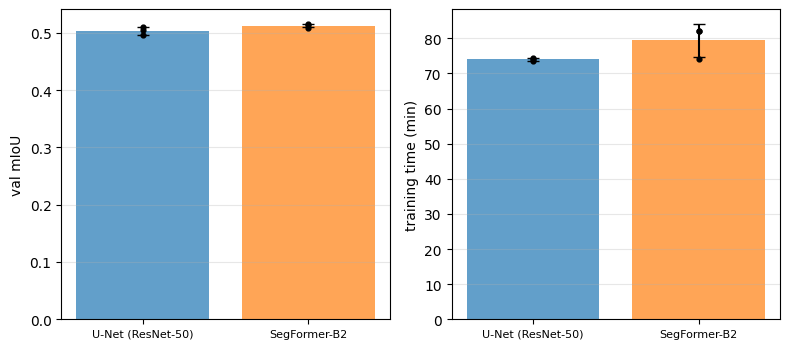

In [23]:
# Experiment 1 results. Compute functions (build_*) and plot functions (plot_*) are kept separate.
from IPython.display import Markdown, display


def exp_runs(fractions):
    """Completed runs restricted to the given label fractions (empty frame if there are none)."""
    df = load_runs(Path(cfg.out_dir))
    return df[df.fraction.isin(fractions)] if not df.empty else df


def gap_markdown(g):
    """Markdown table of a paired SegFormer-B2 - U-Net gap (output of paired_gap)."""
    if g.empty:
        return "_no seeds with both models yet_"
    g = g.assign(gap=[pm(m, s, n) for m, s, n in zip(g.gap_mean, g.gap_std, g.n_pairs)])
    return md_table(g[["fraction", "n_pairs", "gap"]])


def build_exp1_table(df):
    """Per-model metrics (mean ± std over seeds) and cost, plus the paired mIoU gap."""
    cols = ["miou", "pixel_acc", "mf1", "train_time_s", "params_m", "gflops", "ms_per_image"]
    agg = mean_std(df, cols)
    rows = []
    for r in agg.itertuples():
        rows.append({"model": LABELS[r.model], "seeds": r.n_seeds,
                     "mIoU": pm(r.miou_mean, r.miou_std, r.n_seeds),
                     "pixel acc": pm(r.pixel_acc_mean, r.pixel_acc_std, r.n_seeds),
                     "mean F1": pm(r.mf1_mean, r.mf1_std, r.n_seeds),
                     "params (M)": f"{r.params_m_mean:.1f}", "GFLOPs/img": f"{r.gflops_mean:.1f}",
                     "train time (min)": f"{r.train_time_s_mean / 60:.0f}", "ms/img": f"{r.ms_per_image_mean:.1f}"})
    return pd.DataFrame(rows), paired_gap(df, "miou")


def plot_exp1(df):
    """Bars (mean over seeds, dots = single seeds) for mIoU and training time."""
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
    for ax, (col, label, scale) in zip(axes, [("miou", "val mIoU", 1.0), ("train_time_s", "training time (min)", 1 / 60)]):
        for j, m in enumerate(MODELS):
            v = df[df.model == m][col] * scale
            ax.bar(j, v.mean(), color=COLORS[m], alpha=0.7, yerr=v.std(ddof=1) if len(v) > 1 else 0, capsize=4)
            ax.scatter([j] * len(v), v, color="k", s=12, zorder=3)
        ax.set_xticks(range(len(MODELS)))
        ax.set_xticklabels([LABELS[m] for m in MODELS], fontsize=8)
        ax.set_ylabel(label)
        ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()


df1 = exp_runs(EXP1_FRACTIONS)
if df1.empty:
    print("Experiment 1 has no completed runs yet.")
else:
    table1, gap1 = build_exp1_table(df1)
    display(Markdown("### Experiment 1: full training set (validation split)\n\n" + md_table(table1)))
    display(Markdown("**Paired gap, SegFormer-B2 − U-Net (mIoU)**\n\n" + gap_markdown(gap1)))
    plot_exp1(df1)


### Experiment 2: Reduced training data (10%, 25%, 100%)
Both models are trained on 10% and 25% of the training images (the 100% runs come from Experiment 1). Subsets are drawn with a fixed seed within the urban and rural domains separately, so both models see identical images. Epochs are scaled by 1/fraction, so every fraction takes about the same number of gradient steps.

Reported: mIoU per fraction, the share of each model's own 100% mIoU that it keeps, and the paired gap per fraction.

In [24]:
# Experiment 2: reduced label fractions. 100% is reused from Experiment 1 (finished runs are skipped).
EXP2_FRACTIONS = [0.25, 0.1]
RUN_EXP2 = True
if RUN_EXP2:
    run_jobs(EXP2_FRACTIONS)



=== run 1/12: unet_r50 fraction=0.25 seed=0 ===
[skip] unet_r50_f0.25_s0: already complete

=== run 2/12: segformer_b2 fraction=0.25 seed=0 ===
[skip] segformer_b2_f0.25_s0: already complete

=== run 3/12: unet_r50 fraction=0.1 seed=0 ===
[skip] unet_r50_f0.1_s0: already complete

=== run 4/12: segformer_b2 fraction=0.1 seed=0 ===
[skip] segformer_b2_f0.1_s0: already complete

=== run 5/12: unet_r50 fraction=0.25 seed=1 ===
[skip] unet_r50_f0.25_s1: already complete

=== run 6/12: segformer_b2 fraction=0.25 seed=1 ===
[skip] segformer_b2_f0.25_s1: already complete

=== run 7/12: unet_r50 fraction=0.1 seed=1 ===
[skip] unet_r50_f0.1_s1: already complete

=== run 8/12: segformer_b2 fraction=0.1 seed=1 ===
[skip] segformer_b2_f0.1_s1: already complete

=== run 9/12: unet_r50 fraction=0.25 seed=2 ===
[skip] unet_r50_f0.25_s2: already complete

=== run 10/12: segformer_b2 fraction=0.25 seed=2 ===
[skip] segformer_b2_f0.25_s2: already complete

=== run 11/12: unet_r50 fraction=0.1 seed=2 ==

### Experiment 2: label fractions (validation split)

| labels | train images | model | seeds | mIoU | mean F1 | share of own 100% mIoU |
|---|---|---|---|---|---|---|
| 100% | 2522 | SegFormer-B2 | 3 | 0.5125 ± 0.0032 | 0.6672 ± 0.0025 | 100.0% |
| 100% | 2522 | U-Net (ResNet-50) | 3 | 0.5037 ± 0.0069 | 0.6619 ± 0.0088 | 100.0% |
| 25% | 631 | SegFormer-B2 | 3 | 0.5055 ± 0.0100 | 0.6582 ± 0.0106 | 98.6% |
| 25% | 631 | U-Net (ResNet-50) | 3 | 0.4731 ± 0.0035 | 0.6289 ± 0.0058 | 93.9% |
| 10% | 253 | SegFormer-B2 | 3 | 0.5110 ± 0.0080 | 0.6637 ± 0.0090 | 99.7% |
| 10% | 253 | U-Net (ResNet-50) | 3 | 0.4728 ± 0.0090 | 0.6324 ± 0.0084 | 93.8% |


**Paired gap, SegFormer-B2 − U-Net (mIoU), per fraction**

| fraction | n_pairs | gap |
|---|---|---|
| 0.1 | 3 | 0.0382 ± 0.0132 |
| 0.25 | 3 | 0.0324 ± 0.0066 |
| 1.0 | 3 | 0.0088 ± 0.0037 |


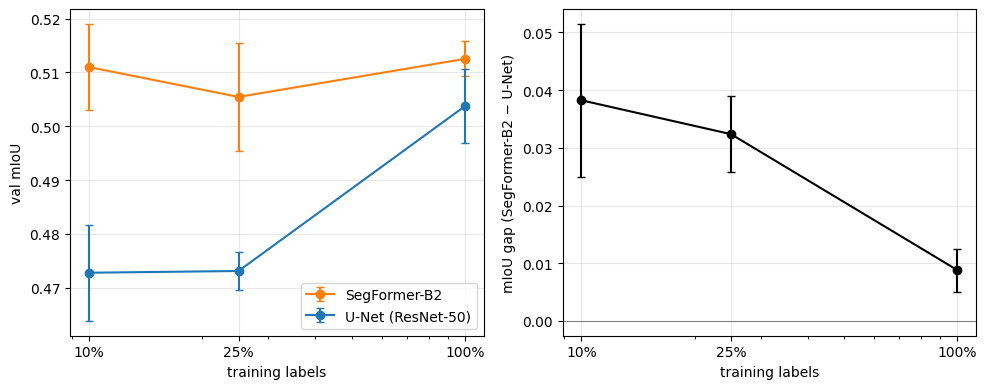

In [25]:
# Experiment 2 results.
def build_exp2_table(df):
    """mIoU per model and fraction (mean ± std over seeds) and the share kept relative to that model's 100% run."""
    agg = mean_std(df, ["miou", "pixel_acc", "mf1"])
    n_img = df.groupby("fraction").n_train_images.first()
    full = agg[agg.fraction == agg.fraction.max()].set_index("model").miou_mean
    rows = []
    for r in agg.sort_values(["fraction", "model"], ascending=[False, True]).itertuples():
        rows.append({"labels": f"{r.fraction * 100:g}%", "train images": int(n_img[r.fraction]), "model": LABELS[r.model],
                     "seeds": r.n_seeds, "mIoU": pm(r.miou_mean, r.miou_std, r.n_seeds),
                     "mean F1": pm(r.mf1_mean, r.mf1_std, r.n_seeds),
                     "share of own 100% mIoU": f"{100 * r.miou_mean / full[r.model]:.1f}%"})
    return pd.DataFrame(rows), paired_gap(df, "miou")


def plot_exp2(df):
    """Left: mIoU vs label fraction per model. Right: paired SegFormer-B2 - U-Net gap vs fraction."""
    agg = mean_std(df, ["miou"])
    fracs = sorted(df.fraction.unique())
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for m, d in agg.groupby("model"):
        d = d.sort_values("fraction")
        axes[0].errorbar(d.fraction * 100, d.miou_mean, yerr=d.miou_std.fillna(0), marker="o", capsize=3,
                         label=LABELS[m], color=COLORS[m])
    gap = paired_gap(df, "miou")
    if not gap.empty:
        axes[1].errorbar(gap.fraction * 100, gap.gap_mean, yerr=gap.gap_std.fillna(0), marker="o", capsize=3, color="k")
        axes[1].axhline(0, color="gray", lw=0.8)
    for ax, ylab in zip(axes, ["val mIoU", "mIoU gap (SegFormer-B2 − U-Net)"]):
        ax.set_xscale("log")
        ax.set_xticks([f * 100 for f in fracs])
        ax.set_xticklabels([f"{f * 100:g}%" for f in fracs])
        ax.set_xlabel("training labels")
        ax.set_ylabel(ylab)
        ax.grid(alpha=0.3)
    axes[0].legend()
    fig.tight_layout()
    plt.show()


df2 = exp_runs(sorted(set(EXP1_FRACTIONS + EXP2_FRACTIONS)))
if df2.empty or df2.fraction.nunique() < 2:
    print("Experiment 2 needs completed runs for at least two label fractions.")
else:
    table2, gap2 = build_exp2_table(df2)
    display(Markdown("### Experiment 2: label fractions (validation split)\n\n" + md_table(table2)))
    display(Markdown("**Paired gap, SegFormer-B2 − U-Net (mIoU), per fraction**\n\n" + gap_markdown(gap2)))
    plot_exp2(df2)


### Experiment 3: Urban vs Rural performance and per-class results
No extra training: this reads the validation metrics already stored for every run in Experiments 1 and 2 (overall, urban and rural, per class).

Reported: urban and rural mIoU per model and fraction, which model is ahead in each domain, per-class IoU overall and per domain, and example predictions next to the ground truth masks.

### Experiment 3a: urban vs rural mIoU (validation split)

| labels | model | seeds | urban mIoU | rural mIoU | rural − urban |
|---|---|---|---|---|---|
| 100% | SegFormer-B2 | 3 | 0.5753 ± 0.0008 | 0.4022 ± 0.0067 | -0.1731 |
| 100% | U-Net (ResNet-50) | 3 | 0.5365 ± 0.0170 | 0.4382 ± 0.0289 | -0.0982 |
| 25% | SegFormer-B2 | 3 | 0.5424 ± 0.0055 | 0.4283 ± 0.0174 | -0.1141 |
| 25% | U-Net (ResNet-50) | 3 | 0.5276 ± 0.0050 | 0.3953 ± 0.0041 | -0.1323 |
| 10% | SegFormer-B2 | 3 | 0.5378 ± 0.0106 | 0.4486 ± 0.0138 | -0.0892 |
| 10% | U-Net (ResNet-50) | 3 | 0.5081 ± 0.0057 | 0.4027 ± 0.0096 | -0.1055 |


**Model ahead per domain (by mean mIoU)**

| labels | urban: model ahead | rural: model ahead |
|---|---|---|
| 10% | SegFormer-B2 | SegFormer-B2 |
| 25% | SegFormer-B2 | SegFormer-B2 |
| 100% | SegFormer-B2 | U-Net (ResNet-50) |


**Paired gap, SegFormer-B2 − U-Net, urban mIoU**

| fraction | n_pairs | gap |
|---|---|---|
| 0.1 | 3 | 0.0297 ± 0.0049 |
| 0.25 | 3 | 0.0148 ± 0.0099 |
| 1.0 | 3 | 0.0388 ± 0.0163 |


**Paired gap, SegFormer-B2 − U-Net, rural mIoU**

| fraction | n_pairs | gap |
|---|---|---|
| 0.1 | 3 | 0.0459 ± 0.0234 |
| 0.25 | 3 | 0.0330 ± 0.0148 |
| 1.0 | 3 | -0.0360 ± 0.0223 |


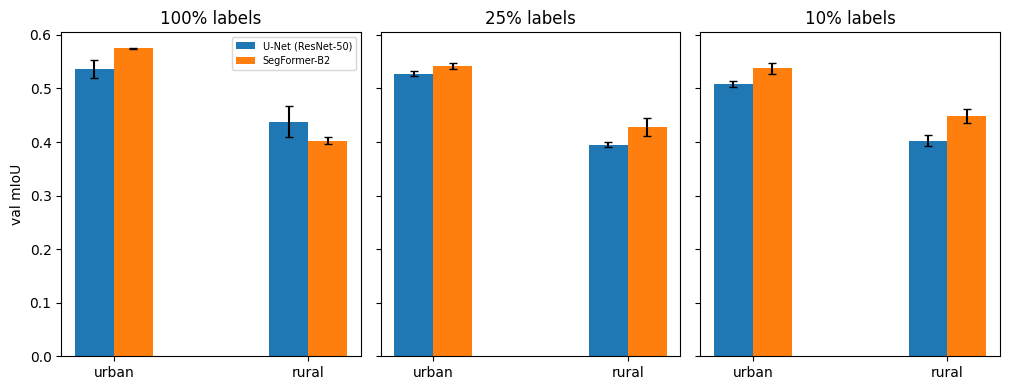

### Experiment 3b: per-class IoU, overall (100% labels)

| class | U-Net (ResNet-50) | SegFormer-B2 | SegFormer − U-Net |
|---|---|---|---|
| background | 0.5230 ± 0.0138 | 0.5413 ± 0.0025 | +0.0183 |
| building | 0.6287 ± 0.0253 | 0.6460 ± 0.0036 | +0.0173 |
| road | 0.5160 ± 0.0072 | 0.5591 ± 0.0065 | +0.0431 |
| water | 0.6626 ± 0.0293 | 0.6731 ± 0.0178 | +0.0106 |
| barren | 0.3105 ± 0.0537 | 0.2815 ± 0.0193 | -0.0290 |
| forest | 0.4051 ± 0.0295 | 0.3757 ± 0.0151 | -0.0294 |
| agriculture | 0.4803 ± 0.0221 | 0.5110 ± 0.0113 | +0.0307 |


### Experiment 3b: per-class IoU, urban (100% labels)

| class | U-Net (ResNet-50) | SegFormer-B2 | SegFormer − U-Net |
|---|---|---|---|
| background | 0.4280 ± 0.0196 | 0.4513 ± 0.0097 | +0.0233 |
| building | 0.6434 ± 0.0225 | 0.6758 ± 0.0071 | +0.0324 |
| road | 0.5922 ± 0.0285 | 0.6349 ± 0.0146 | +0.0427 |
| water | 0.6972 ± 0.0232 | 0.7403 ± 0.0098 | +0.0431 |
| barren | 0.4129 ± 0.0197 | 0.4230 ± 0.0145 | +0.0101 |
| forest | 0.5131 ± 0.0298 | 0.5433 ± 0.0021 | +0.0302 |
| agriculture | 0.4683 ± 0.0603 | 0.5583 ± 0.0312 | +0.0899 |


### Experiment 3b: per-class IoU, rural (100% labels)

| class | U-Net (ResNet-50) | SegFormer-B2 | SegFormer − U-Net |
|---|---|---|---|
| background | 0.5634 ± 0.0121 | 0.5762 ± 0.0021 | +0.0128 |
| building | 0.5929 ± 0.0349 | 0.5720 ± 0.0064 | -0.0209 |
| road | 0.3549 ± 0.0386 | 0.3833 ± 0.0130 | +0.0285 |
| water | 0.6394 ± 0.0346 | 0.6271 ± 0.0368 | -0.0122 |
| barren | 0.2213 ± 0.0618 | 0.1226 ± 0.0190 | -0.0987 |
| forest | 0.2099 ± 0.1158 | 0.0509 ± 0.0471 | -0.1590 |
| agriculture | 0.4857 ± 0.0405 | 0.4832 ± 0.0078 | -0.0024 |


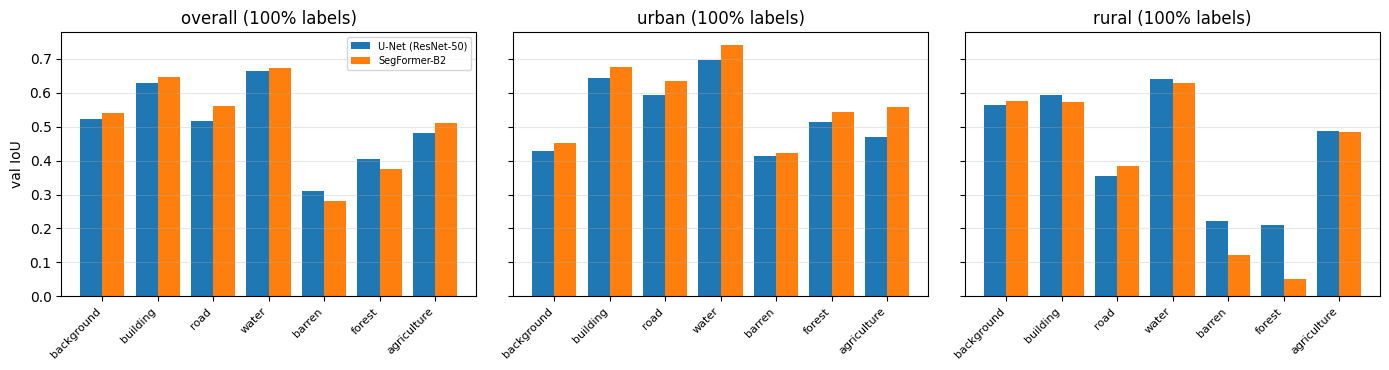

In [26]:
# Experiment 3 results: urban vs rural, then per class.
def build_domain_table(df):
    """Urban / rural mIoU per fraction and model (mean ± std), and which model is ahead in each domain."""
    agg = mean_std(df, ["miou", "urban_miou", "rural_miou"])
    rows = []
    for r in agg.sort_values(["fraction", "model"], ascending=[False, True]).itertuples():
        rows.append({"labels": f"{r.fraction * 100:g}%", "model": LABELS[r.model], "seeds": r.n_seeds,
                     "urban mIoU": pm(r.urban_miou_mean, r.urban_miou_std, r.n_seeds),
                     "rural mIoU": pm(r.rural_miou_mean, r.rural_miou_std, r.n_seeds),
                     "rural − urban": f"{r.rural_miou_mean - r.urban_miou_mean:+.4f}"})
    ahead = []
    for f, d in agg.groupby("fraction", sort=False):
        d = d.set_index("model")
        if {"unet_r50", "segformer_b2"} <= set(d.index):
            ahead.append({"labels": f"{f * 100:g}%",
                          "urban: model ahead": LABELS[d.urban_miou_mean.idxmax()],
                          "rural: model ahead": LABELS[d.rural_miou_mean.idxmax()]})
    return pd.DataFrame(rows), pd.DataFrame(ahead)


def load_domain_class_iou(exp_dir):
    """Long table (model, fraction, seed, domain, class, iou) from the stored validation metrics of finished runs."""
    rows = []
    for p in sorted(Path(exp_dir).glob("*/metrics.json")):
        m = read_json(p)
        if not m.get("complete"):
            continue
        for dom in ("overall", "urban", "rural"):
            for c, v in m["val"][dom]["iou"].items():
                rows.append({"model": m["config"]["model"], "fraction": m["config"]["fraction"],
                             "seed": m["config"]["seed"], "domain": dom, "class": c,
                             "iou": np.nan if v is None else v})
    return pd.DataFrame(rows)


def build_class_table(dc, fraction, domain="overall"):
    """Per-class IoU (mean ± std over seeds) for both models and their difference, for one fraction and domain."""
    d = dc[(dc.fraction == fraction) & (dc.domain == domain)]
    g = d.groupby(["class", "model"]).iou.agg(["mean", "std", "count"]).reset_index()
    rows = []
    for c in CLASS_NAMES:
        row, means = {"class": c}, {}
        for m in MODELS:
            r = g[(g["class"] == c) & (g.model == m)]
            if r.empty:
                row[LABELS[m]] = "n/a"
                continue
            r = r.iloc[0]
            means[m] = r["mean"]
            row[LABELS[m]] = pm(r["mean"], r["std"], int(r["count"]))
        row["SegFormer − U-Net"] = f"{means['segformer_b2'] - means['unet_r50']:+.4f}" if len(means) == 2 else "n/a"
        rows.append(row)
    return pd.DataFrame(rows)


def plot_domain_miou(df):
    """Urban vs rural mIoU bars per model, one panel per label fraction."""
    agg = mean_std(df, ["urban_miou", "rural_miou"])
    fracs = sorted(agg.fraction.unique(), reverse=True)
    fig, axes = plt.subplots(1, len(fracs), figsize=(3.4 * len(fracs), 4), sharey=True, squeeze=False)
    for ax, f in zip(axes[0], fracs):
        d = agg[agg.fraction == f]
        for j, dom in enumerate(("urban", "rural")):
            for k, m in enumerate(MODELS):
                r = d[d.model == m]
                if r.empty:
                    continue
                r = r.iloc[0]
                err = r[f"{dom}_miou_std"]
                ax.bar(j + 0.2 * (k - 0.5), r[f"{dom}_miou_mean"], 0.2, yerr=0 if pd.isna(err) else err,
                       color=COLORS[m], capsize=3, label=LABELS[m] if j == 0 else None)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["urban", "rural"])
        ax.set_title(f"{f * 100:g}% labels")
    axes[0][0].set_ylabel("val mIoU")
    axes[0][0].legend(fontsize=7)
    fig.tight_layout()
    plt.show()


def plot_class_iou(dc, fraction):
    """Per-class IoU bars for both models: overall, urban and rural."""
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
    x = np.arange(len(CLASS_NAMES))
    for ax, dom in zip(axes, ("overall", "urban", "rural")):
        d = dc[(dc.fraction == fraction) & (dc.domain == dom)].groupby(["model", "class"]).iou.mean()
        for k, m in enumerate(MODELS):
            vals = [d.get((m, c), np.nan) for c in CLASS_NAMES]
            ax.bar(x + 0.4 * (k - 0.5), vals, 0.4, color=COLORS[m], label=LABELS[m])
        ax.set_xticks(x)
        ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right", fontsize=8)
        ax.set_title(f"{dom} ({fraction * 100:g}% labels)")
        ax.grid(axis="y", alpha=0.3)
    axes[0].set_ylabel("val IoU")
    axes[0].legend(fontsize=7)
    fig.tight_layout()
    plt.show()


df3 = exp_runs(sorted(set(EXP1_FRACTIONS + EXP2_FRACTIONS)))
if df3.empty:
    print("Experiment 3 needs completed runs from Experiments 1 and 2.")
else:
    top_fraction = df3.fraction.max()
    dom_table, dom_ahead = build_domain_table(df3)
    display(Markdown("### Experiment 3a: urban vs rural mIoU (validation split)\n\n" + md_table(dom_table)))
    display(Markdown("**Model ahead per domain (by mean mIoU)**\n\n" + md_table(dom_ahead)))
    for dom in ("urban", "rural"):
        display(Markdown(f"**Paired gap, SegFormer-B2 − U-Net, {dom} mIoU**\n\n" + gap_markdown(paired_gap(df3, f"{dom}_miou"))))
    plot_domain_miou(df3)

    dc = load_domain_class_iou(cfg.out_dir)
    for dom in ("overall", "urban", "rural"):
        display(Markdown(f"### Experiment 3b: per-class IoU, {dom} ({top_fraction * 100:g}% labels)\n\n"
                         + md_table(build_class_table(dc, top_fraction, dom))))
    plot_class_iou(dc, top_fraction)


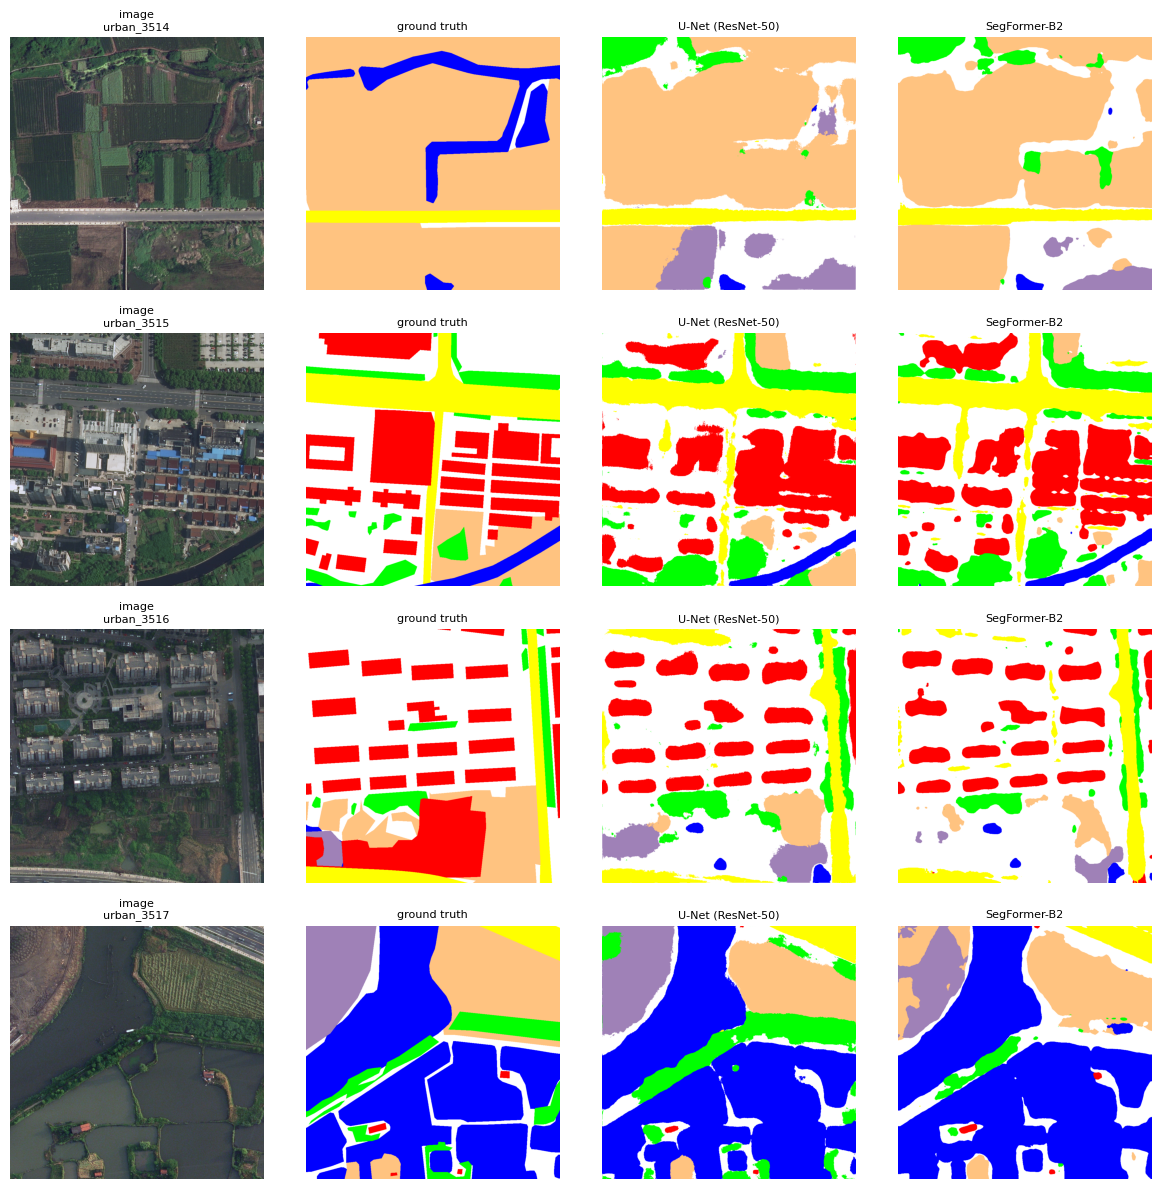

Colours: white=background, red=building, yellow=road, blue=water, purple=barren, green=forest, orange=agriculture, black=no-data


In [27]:
# Experiment 3c: example predictions next to the ground truth (validation images, first full-data seed).
def colorize(raw):
    """LoveDA raw mask values (0 = no-data, 1..7 = classes) -> RGB, using the official LoveDA colours."""
    pal = np.array([[0, 0, 0], [255, 255, 255], [255, 0, 0], [255, 255, 0], [0, 0, 255],
                    [159, 129, 183], [0, 255, 0], [255, 195, 128]], dtype=np.uint8)
    return pal[raw]


def find_prediction_dir(model, fraction=1.0, seed=None):
    """Prediction folder written by a finished run (None if it has none)."""
    run_dir = replace(cfg, model=model, fraction=fraction, seed=SEEDS[0] if seed is None else seed).run_dir
    dirs = sorted(p for p in (run_dir / "predictions").glob("*") if p.is_dir()) if (run_dir / "predictions").is_dir() else []
    return dirs[0] if dirs else None


def plot_examples(n=4):
    """Rows = validation images; columns = image, ground truth, U-Net prediction, SegFormer-B2 prediction."""
    pred_dirs = {m: find_prediction_dir(m) for m in MODELS}
    if not all(pred_dirs.values()):
        print("No saved predictions found; finish the full-data runs of Experiment 1 first.")
        return
    by_id = {s.id: s for s in get_spec(cfg.dataset).scan(DATA_ROOT, "Val", True)}
    ids = sorted(p.stem for p in pred_dirs[MODELS[0]].glob("*.png") if (pred_dirs[MODELS[1]] / p.name).exists())[:n]
    fig, axes = plt.subplots(len(ids), 4, figsize=(12, 3 * len(ids)), squeeze=False)
    for row, sid in zip(axes, ids):
        s = by_id[sid]
        panels = [("image", np.array(Image.open(s.image).convert("RGB"))),
                  ("ground truth", colorize(np.array(Image.open(s.mask)))),
                  (LABELS[MODELS[0]], colorize(np.array(Image.open(pred_dirs[MODELS[0]] / f"{sid}.png")))),
                  (LABELS[MODELS[1]], colorize(np.array(Image.open(pred_dirs[MODELS[1]] / f"{sid}.png"))))]
        for ax, (title, img) in zip(row, panels):
            ax.imshow(img)
            ax.set_title(f"{title}\n{sid}" if title == "image" else title, fontsize=8)
            ax.axis("off")
    fig.tight_layout()
    plt.show()
    print("Colours: white=background, red=building, yellow=road, blue=water, purple=barren, green=forest, orange=agriculture, black=no-data")


plot_examples(n=4)


## 9. Combined results
All completed runs (every experiment) aggregated into one summary table and figure set, written to Drive. The tables above are the per-experiment views.

wrote tables and figures for 18 runs to /content/drive/MyDrive/segformer_vs_unet/results_standard/


# Results (validation split)
Generated from 18 completed runs. mean ± sample std over seeds (ddof=1). All numbers are measured on the LoveDA **validation** split, which was also used for LR tuning and checkpoint selection (see README).
## Overall metrics
| fraction | model | seeds | miou | pixel_acc | mf1 |
|---|---|---|---|---|---|
| 1 | SegFormer-B2 | 3 | 0.5125 ± 0.0032 | 0.6959 ± 0.0015 | 0.6672 ± 0.0025 |
| 1 | U-Net (ResNet-50) | 3 | 0.5037 ± 0.0069 | 0.6794 ± 0.0042 | 0.6619 ± 0.0088 |
| 0.25 | SegFormer-B2 | 3 | 0.5055 ± 0.0100 | 0.6961 ± 0.0086 | 0.6582 ± 0.0106 |
| 0.25 | U-Net (ResNet-50) | 3 | 0.4731 ± 0.0035 | 0.6637 ± 0.0081 | 0.6289 ± 0.0058 |
| 0.1 | SegFormer-B2 | 3 | 0.5110 ± 0.0080 | 0.7046 ± 0.0089 | 0.6637 ± 0.0090 |
| 0.1 | U-Net (ResNet-50) | 3 | 0.4728 ± 0.0090 | 0.6653 ± 0.0094 | 0.6324 ± 0.0084 |

## Urban vs rural mIoU
| fraction | model | seeds | urban_miou | rural_miou |
|---|---|---|---|---|
| 1 | SegFormer-B2 | 3 | 0.5753 ± 0.0008 | 0.4022 ± 0.0067 |
| 1 | U-Net (ResNet-50) | 3 | 0.5365 ± 0.0170 | 0.4382 ± 0.0289 |
| 0.25 | SegFormer-B2 | 3 | 0.5424 ± 0.0055 | 0.4283 ± 0.0174 |
| 0.25 | U-Net (ResNet-50) | 3 | 0.5276 ± 0.0050 | 0.3953 ± 0.0041 |
| 0.1 | SegFormer-B2 | 3 | 0.5378 ± 0.0106 | 0.4486 ± 0.0138 |
| 0.1 | U-Net (ResNet-50) | 3 | 0.5081 ± 0.0057 | 0.4027 ± 0.0096 |

## Per-class IoU
| fraction | model | seeds | iou_background | iou_building | iou_road | iou_water | iou_barren | iou_forest | iou_agriculture |
|---|---|---|---|---|---|---|---|---|---|
| 1 | SegFormer-B2 | 3 | 0.5413 ± 0.0025 | 0.6460 ± 0.0036 | 0.5591 ± 0.0065 | 0.6731 ± 0.0178 | 0.2815 ± 0.0193 | 0.3757 ± 0.0151 | 0.5110 ± 0.0113 |
| 1 | U-Net (ResNet-50) | 3 | 0.5230 ± 0.0138 | 0.6287 ± 0.0253 | 0.5160 ± 0.0072 | 0.6626 ± 0.0293 | 0.3105 ± 0.0537 | 0.4051 ± 0.0295 | 0.4803 ± 0.0221 |
| 0.25 | SegFormer-B2 | 3 | 0.5295 ± 0.0080 | 0.6376 ± 0.0121 | 0.5300 ± 0.0024 | 0.6781 ± 0.0012 | 0.2222 ± 0.0342 | 0.4019 ± 0.0211 | 0.5390 ± 0.0444 |
| 0.25 | U-Net (ResNet-50) | 3 | 0.5052 ± 0.0100 | 0.6100 ± 0.0138 | 0.4855 ± 0.0279 | 0.6223 ± 0.0232 | 0.1840 ± 0.0441 | 0.4160 ± 0.0081 | 0.4886 ± 0.0151 |
| 0.1 | SegFormer-B2 | 3 | 0.5273 ± 0.0148 | 0.6282 ± 0.0065 | 0.5194 ± 0.0133 | 0.6787 ± 0.0198 | 0.2358 ± 0.0437 | 0.4022 ± 0.0138 | 0.5855 ± 0.0294 |
| 0.1 | U-Net (ResNet-50) | 3 | 0.4990 ± 0.0219 | 0.5569 ± 0.0382 | 0.4715 ± 0.0145 | 0.6438 ± 0.0326 | 0.2490 ± 0.0340 | 0.3789 ± 0.0245 | 0.5103 ± 0.0126 |

## Paired gap, SegFormer-B2 minus U-Net (mIoU, paired by seed)
| fraction | n_pairs | gap |
|---|---|---|
| 0.1 | 3 | 0.0382 ± 0.0132 |
| 0.25 | 3 | 0.0324 ± 0.0066 |
| 1.0 | 3 | 0.0088 ± 0.0037 |

### urban domain
| fraction | n_pairs | gap |
|---|---|---|
| 0.1 | 3 | 0.0297 ± 0.0049 |
| 0.25 | 3 | 0.0148 ± 0.0099 |
| 1.0 | 3 | 0.0388 ± 0.0163 |

### rural domain
| fraction | n_pairs | gap |
|---|---|---|
| 0.1 | 3 | 0.0459 ± 0.0234 |
| 0.25 | 3 | 0.0330 ± 0.0148 |
| 1.0 | 3 | -0.0360 ± 0.0223 |

## Efficiency (runs at fraction 1, mean over seeds)
| model | params_m | gflops | train_time_s | ms_per_image | images_per_s |
|---|---|---|---|---|---|
| SegFormer-B2 | 27.352 | 121.077 | 4765.857 | 57.477 | 17.424 |
| U-Net (ResNet-50) | 32.522 | 85.513 | 4440.952 | 49.72 | 20.141 |

GFLOPs counted by torch FlopCounterMode for one 3x512x512 image (1 MAC = 2 FLOPs); inference timing is fp32, batch size 1, same device for both models. Devices: Tesla T4


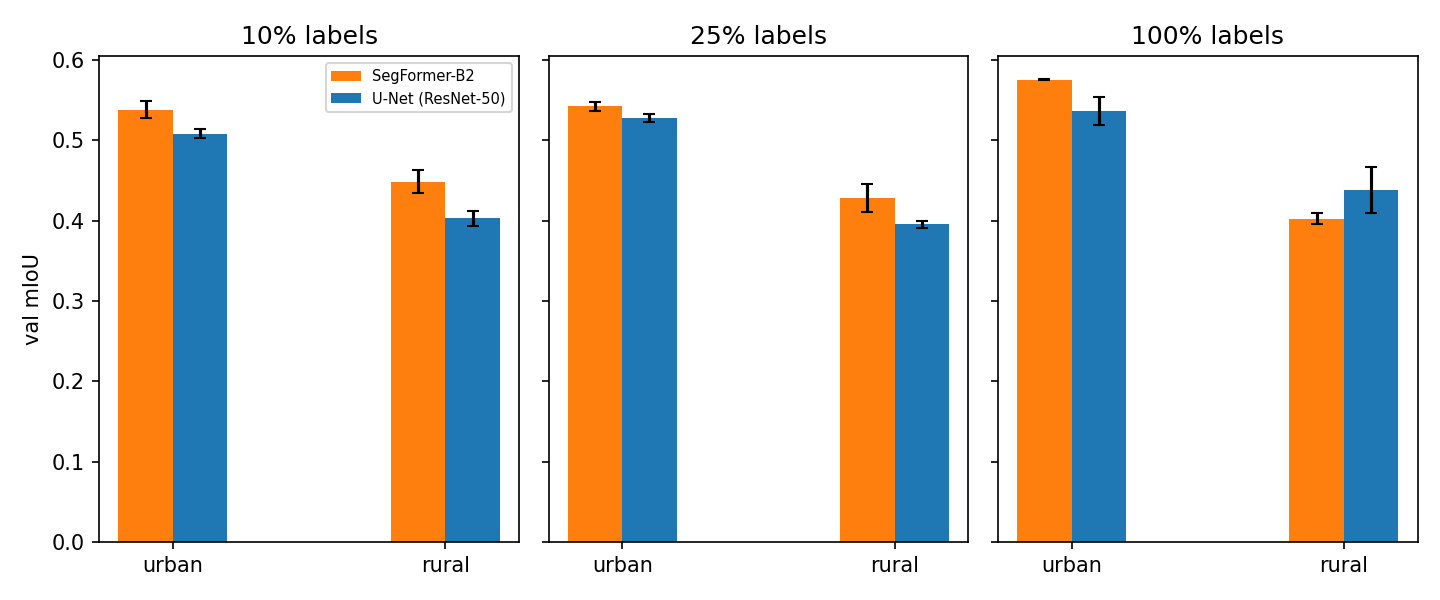

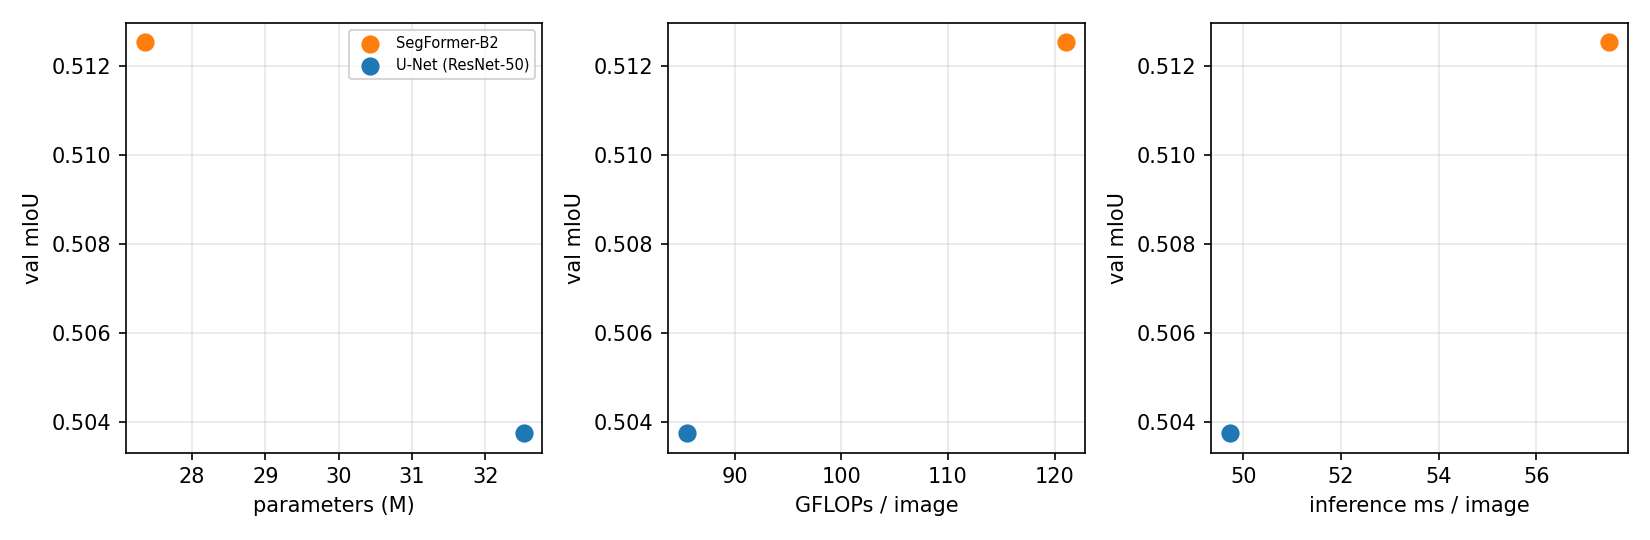

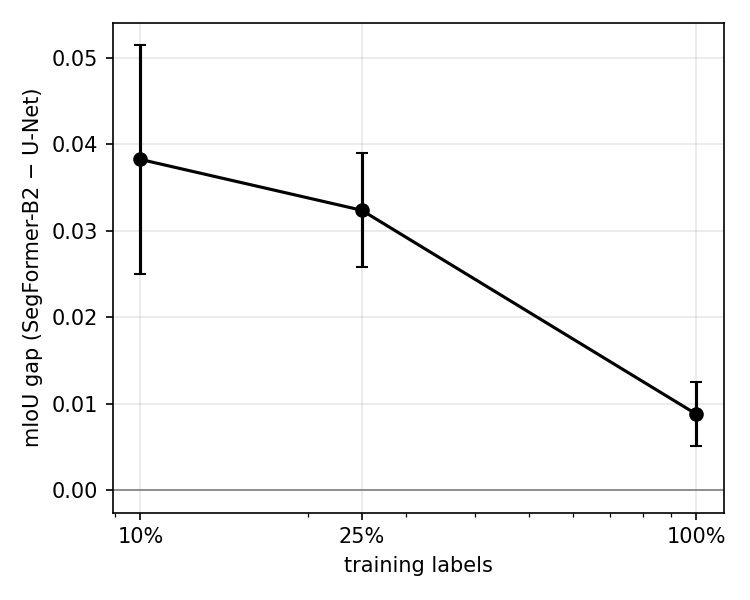

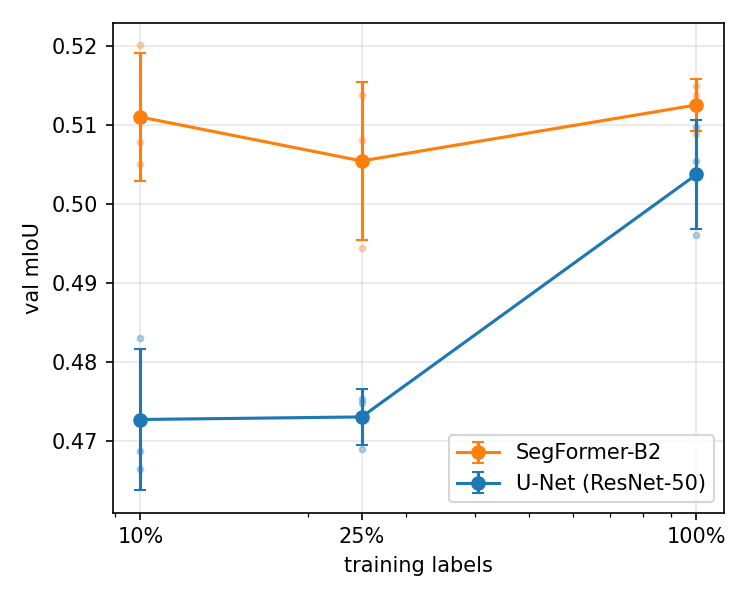

In [28]:
# 6) Tables and figures from completed runs (nothing is concluded automatically).
from IPython.display import Image as IPImage, Markdown, display

if any(Path(cfg.out_dir).glob("*/metrics.json")):
    df = aggregate_runs(cfg.out_dir, str(RESULTS_DIR))
    display(Markdown((RESULTS_DIR / "summary.md").read_text()))
    for fig in sorted((RESULTS_DIR / "figures").glob("*.png")):
        display(IPImage(filename=str(fig)))
else:
    print("No completed study runs yet.")

In [29]:
# 7) Optional: download the tables/figures to your computer (they are also on Drive).
try:
    from google.colab import files
    shutil.make_archive("/content/results", "zip", RESULTS_DIR)
    files.download("/content/results.zip")
except Exception as e:  # noqa: BLE001
    print("skipped:", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Visualization using Gradio

In [32]:
!pip install gradio segmentation-models-pytorch transformers

import numpy as np, torch, torch.nn.functional as F
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
import gradio as gr
import segmentation_models_pytorch as smp
from transformers import SegformerForSemanticSegmentation

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CLASSES = ["background", "building", "road", "water", "barren", "forest", "agriculture"]
PALETTE = np.array([[255,255,255],[255,0,0],[255,255,0],[0,0,255],
                    [159,129,183],[0,255,0],[255,195,128]], dtype=np.uint8)
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

# ---------- build ----------
def build_unet(ckpt_path):
    m = smp.Unet("resnet50", encoder_weights=None, classes=7)
    sd = torch.load(ckpt_path, map_location="cpu")
    m.load_state_dict(sd.get("model", sd))          # adapt key to how you saved it
    return m.to(DEVICE).eval()

def build_segformer(ckpt_path):
    m = SegformerForSemanticSegmentation.from_pretrained("nvidia/mit-b2", num_labels=7)
    checkpoint = torch.load(ckpt_path, map_location="cpu")
    sd = checkpoint.get("model", checkpoint)
    # Training wraps the Hugging Face model as `net`, prefixing its state-dict keys.
    sd = {key.removeprefix("net."): value for key, value in sd.items()}
    m.load_state_dict(sd)
    return m.to(DEVICE).eval()

# ---------- compute ----------
def preprocess(img: np.ndarray) -> torch.Tensor:
    x = torch.from_numpy(img).permute(2, 0, 1)[None].float() / 255.0
    return ((x - MEAN) / STD).to(DEVICE)

@torch.no_grad()
def predict_unet(model, x):
    h, w = x.shape[-2:]
    ph, pw = (32 - h % 32) % 32, (32 - w % 32) % 32     # U-Net needs multiples of 32
    out = model(F.pad(x, (0, pw, 0, ph)))[..., :h, :w]
    return out.argmax(1)[0].cpu().numpy()

@torch.no_grad()
def predict_segformer(model, x):
    logits = model(pixel_values=x).logits                # 1/4 resolution
    logits = F.interpolate(logits, size=x.shape[-2:], mode="bilinear", align_corners=False)
    return logits.argmax(1)[0].cpu().numpy()

def class_share(mask):
    return np.bincount(mask.ravel(), minlength=7) / mask.size * 100

def disagreement(mask_a, mask_b):
    return mask_a != mask_b

# ---------- plot ----------
def colorize(mask):
    return PALETTE[mask]

def overlay(img, mask, alpha=0.5):
    return (img * (1 - alpha) + colorize(mask) * alpha).astype(np.uint8)

def disagreement_image(img, diff):
    out = (img * 0.5).astype(np.uint8)
    out[diff] = [255, 0, 0]
    return out

def plot_class_share(share_a, share_b):
    fig, ax = plt.subplots(figsize=(6, 3.5))
    xs = np.arange(7)
    ax.bar(xs - 0.2, share_a, 0.4, label="U-Net")
    ax.bar(xs + 0.2, share_b, 0.4, label="SegFormer-B2")
    ax.set_xticks(xs); ax.set_xticklabels(CLASSES, rotation=30, ha="right")
    ax.set_ylabel("% of pixels"); ax.legend(); fig.tight_layout()
    return fig

def plot_legend():
    fig, ax = plt.subplots(figsize=(6, 0.6)); ax.axis("off")
    for i, (c, col) in enumerate(zip(CLASSES, PALETTE / 255)):
        ax.add_patch(plt.Rectangle((i, 0), 0.9, 1, color=col))
        ax.text(i + 0.45, -0.3, c, ha="center", va="top", fontsize=7)
    ax.set_xlim(0, 7); ax.set_ylim(-1, 1)
    return fig

# ---------- UI ----------
def make_app(unet, segformer):
    def run(img, alpha):
        if img is None:
            return [None] * 5
        x = preprocess(img)
        ma, mb = predict_unet(unet, x), predict_segformer(segformer, x)
        diff = disagreement(ma, mb)
        agree = 100 - diff.mean() * 100
        return (overlay(img, ma, alpha), overlay(img, mb, alpha),
                disagreement_image(img, diff),
                plot_class_share(class_share(ma), class_share(mb)),
                f"Models agree on {agree:.1f}% of pixels")

    with gr.Blocks(title="U-Net vs SegFormer-B2 on LoveDA") as app:
        gr.Markdown("## U-Net (ResNet-50) vs SegFormer-B2: land cover segmentation")
        with gr.Row():
            inp = gr.Image(type="numpy", label="Satellite tile", height=380)
            alpha = gr.Slider(0, 1, 0.5, label="Overlay opacity")
        btn = gr.Button("Segment", variant="primary")
        with gr.Row():
            o1 = gr.Image(label="U-Net"); o2 = gr.Image(label="SegFormer-B2")
            o3 = gr.Image(label="Disagreement (red)")
        agree_txt = gr.Textbox(label="Agreement", interactive=False)
        plot = gr.Plot(label="Class share")
        gr.Plot(value=plot_legend(), label="Legend")
        btn.click(run, [inp, alpha], [o1, o2, o3, plot, agree_txt])
    return app

# Training stores best checkpoints under BASE/experiments_<PROFILE>/<model>_f1_s0/checkpoints/.
experiment_dir = BASE / f"experiments_{PROFILE}"
unet_checkpoint = experiment_dir / "unet_r50_f1_s0" / "checkpoints" / "best.pt"
segformer_checkpoint = experiment_dir / "segformer_b2_f1_s0" / "checkpoints" / "best.pt"
missing = [path for path in (unet_checkpoint, segformer_checkpoint) if not path.is_file()]
if missing:
    missing_paths = "\n".join(str(path) for path in missing)
    raise FileNotFoundError(
        f"Checkpoint(s) not found:\n{missing_paths}\n"
        f"Run the {PROFILE!r} profile training cells first, or update these checkpoint paths."
    )

unet = build_unet(unet_checkpoint)
segformer = build_segformer(segformer_checkpoint)
make_app(unet, segformer).launch(share=True)

[transformers] You passed `num_labels=7` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b2
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.bias                                         | UNEXPECTED | 
classifier.weight                                       | UNEXPECTED | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.classifier.weight                           

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5f03ee866d90947376.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import numpy as np, matplotlib.pyplot as plt, gradio as gr
from PIL import Image

# ---------- look & feel ----------
CLASSES = ["background", "building", "road", "water", "barren", "forest", "agriculture"]
FRIENDLY = {"background": "🟫 Other stuff", "building": "🏠 Buildings", "road": "🛣️ Roads",
            "water": "💧 Water", "barren": "🏜️ Bare land", "forest": "🌳 Forest",
            "agriculture": "🌾 Farmland"}
HEX = ["#d9d4c7", "#e4572e", "#f2c14e", "#3a86c8", "#a78a7f", "#2d6a4f", "#b7e27a"]
PALETTE = np.array([[int(h[i:i+2], 16) for i in (1, 3, 5)] for h in HEX], dtype=np.uint8)

# ---------- theme: "field notes" look ----------
INK, PAPER, SAGE, GOLD, CLAY = "#14213d", "#eef2ec", "#cfdccb", "#e9a820", "#c8553d"

THEME = gr.themes.Base(
    primary_hue=gr.themes.Color(*["#f4f8f1", "#e3ecde", "#cfdccb", "#aec4a8", "#86a37f",
                                  "#5f8259", "#476843", "#36503a", "#273a2b", "#1b291f", "#111a14"]),
    neutral_hue="slate",
    font=[gr.themes.GoogleFont("Inter"), "sans-serif"],
).set(
    body_background_fill=PAPER, block_background_fill="#fbfcf9", block_border_width="1px",
    block_border_color="#d5ddd0", block_radius="10px", block_shadow="none",
    button_primary_background_fill=INK, button_primary_background_fill_hover="#26365f",
    button_primary_text_color="#ffffff",
)

CSS = f"""
@import url('https://fonts.googleapis.com/css2?family=Fraunces:ital,opsz,wght@0,9..144,500;0,9..144,700;1,9..144,400&display=swap');
:root {{ --ink:{INK}; --soft:#46566f; --cap:#5b6b82; --clay:{CLAY}; --gold:{GOLD}; --rule:{INK}; }}
.dark {{ --ink:#f1efe6; --soft:#aab6cc; --cap:#8fa0ba; --clay:#e8806a; --rule:#f1efe6; }}

.gradio-container {{max-width: 1180px !important; margin: auto;}}
h1,h2,h3,.serif {{font-family:'Fraunces',Georgia,serif !important; color:var(--ink) !important;}}

.hero {{padding:34px 4px 18px; border-bottom:2px solid var(--rule); margin-bottom:22px;}}
.eyebrow {{font-size:.78rem; letter-spacing:.16em; text-transform:uppercase; color:var(--clay); font-weight:600;}}
.hero h1 {{font-size:2.6rem; line-height:1.1; margin:.2em 0;}}
.hero .sub {{font-family:'Fraunces',serif; font-style:italic; font-size:1.15rem; color:var(--soft);}}

/* number + title on one centred line */
.step {{display:flex; align-items:center; gap:16px; margin:28px 0 4px;}}
.step .num {{font-family:'Fraunces',serif; font-size:2rem; line-height:1; color:var(--gold);
            font-weight:700; min-width:2.4rem;}}
.step h2 {{margin:0 !important; padding:0 !important; font-size:1.7rem; line-height:1;}}
.analogy {{font-family:'Fraunces',serif; font-style:italic; color:var(--soft); margin:0 0 12px 3.4rem;}}

.caption {{font-family:'Fraunces',serif; font-style:italic; font-size:.9rem; color:var(--cap); text-align:center;}}
.chip {{display:inline-block; padding:3px 11px; margin:3px; border-radius:6px; font-size:.82rem;
       color:#14213d; border:1px solid rgba(20,33,61,.25);}}
.note {{border-left:4px solid var(--gold); background:rgba(233,168,32,.12); padding:10px 14px; border-radius:0 8px 8px 0;}}
footer {{display:none !important;}}
"""

def hero_html():
    return f"""<div class="hero">
<div class="eyebrow">Satellite image segmentation · CNN vs Transformer</div>
<h1>Land-Cover Detective</h1>
<div class="sub">Two AIs look at the same satellite photo. One reads it like a map with a magnifying glass,
the other glances at the whole picture at once. Who sees the land better?</div></div>"""

def step_html(num, title, analogy):
    return (f'<div class="step"><span class="num">{num}</span><h2>{title}</h2></div>'
            f'<p class="analogy">{analogy}</p>')

def legend_html():
    return "".join(f'<span class="chip" style="background:{h}">{FRIENDLY[c]}</span>'
                   for c, h in zip(CLASSES, HEX))

# ---------- compute ----------
def highlight_classes(img, mask, keep):
    """Colour only the chosen classes; everything else is shown in faded grey."""
    out = np.array(Image.fromarray(img).convert("L").convert("RGB"), dtype=np.float32) * 0.6 + 60
    for c in keep:
        out[mask == c] = PALETTE[c]
    return out.astype(np.uint8)

def render_view(img, mask, view, alpha):
    if view == "Original photo":
        return img
    if view == "Colour map only":
        return PALETTE[mask]
    return (img * (1 - alpha) + PALETTE[mask] * alpha).astype(np.uint8)

def to_label_ids(gt):
    """LoveDA mask: 0 = no-data (ignored), 1..7 -> classes 0..6."""
    gt = gt.astype(np.int64) if gt.ndim == 2 else gt[..., 0].astype(np.int64)
    return np.where(gt == 0, 255, gt - 1)

def per_class_iou(pred, gt):
    valid = gt != 255
    ious = []
    for c in range(7):
        inter = ((pred == c) & (gt == c) & valid).sum()
        union = (((pred == c) | (gt == c)) & valid).sum()
        ious.append(inter / union * 100 if union else np.nan)
    return np.array(ious)

def describe_scene(share_a, share_b, agree, kid):
    top = int(np.argmax((share_a + share_b) / 2))
    name = FRIENDLY[CLASSES[top]]
    pct = (share_a[top] + share_b[top]) / 2
    if kid:
        verdict = ("They almost always agree!" if agree > 85 else
                   "They mostly agree, but argue about some spots." if agree > 70 else
                   "This one is tricky: the two robots disagree a lot!")
        return (f"### 🤖 What the Robots see\nMost of this picture is **{name}** (about {pct:.0f}%). "
                f"{verdict}\n\nThe **red spots** on the third picture are places where the robots gave "
                f"different answers.")
    return (f"### Summary\nDominant class: **{name}** (~{pct:.0f}% of pixels). "
            f"Pixel agreement between models: **{agree:.1f}%**.")

import io

def fig_to_image(fig):
    """Render a matplotlib figure to an opaque RGB array (immune to dark-mode transparency)."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=150, facecolor=fig.get_facecolor(), transparent=False)
    plt.close(fig)
    buf.seek(0)
    return np.array(Image.open(buf).convert("RGB"))

# ---------- plot ----------
CARD_BG, CARD_INK, CARD_GRID = "#f6f4ec", "#14213d", "#d8d4c4"

def style_chart(fig, ax, ylabel=None):
    """Light card + dark text, so labels stay readable in light and dark mode."""
    fig.patch.set_facecolor(CARD_BG); ax.set_facecolor(CARD_BG)
    ax.tick_params(colors=CARD_INK, labelsize=9)
    ax.xaxis.label.set_color(CARD_INK); ax.yaxis.label.set_color(CARD_INK)
    if ylabel: ax.set_ylabel(ylabel, color=CARD_INK)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    for s in ("left", "bottom"): ax.spines[s].set_color(CARD_INK)
    ax.grid(axis="y", color=CARD_GRID, linewidth=0.8); ax.set_axisbelow(True)
    leg = ax.get_legend()
    if leg:
        leg.get_frame().set_facecolor(CARD_BG); leg.get_frame().set_edgecolor(CARD_GRID)
        for t in leg.get_texts(): t.set_color(CARD_INK)
    fig.tight_layout()
    return fig

def _grouped_bars(labels, a, b, ylabel, ylim=None):
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    xs = np.arange(len(labels))
    ax.bar(xs - 0.2, a, 0.4, label="U-Net (CNN)", color="#3a86c8")
    ax.bar(xs + 0.2, b, 0.4, label="SegFormer-B2 (Transformer)", color="#e4572e")
    ax.set_xticks(xs); ax.set_xticklabels(labels, rotation=30 if len(labels) > 3 else 0,
                                          ha="right" if len(labels) > 3 else "center")
    if ylim: ax.set_ylim(*ylim)
    ax.legend(frameon=True)
    return style_chart(fig, ax, ylabel)

def plot_class_share(share_a, share_b):
    return _grouped_bars([FRIENDLY[c] for c in CLASSES], share_a, share_b, "% of the picture")

def plot_iou(iou_a, iou_b):
    return _grouped_bars([FRIENDLY[c] for c in CLASSES], np.nan_to_num(iou_a),
                         np.nan_to_num(iou_b), "IoU score (higher = better)")

def plot_scoreboard():
    """Validation mIoU %, mean over 3 seeds (from the report)."""
    return _grouped_bars(["100% labels", "25% labels", "10% labels"],
                         [50.37, 47.31, 47.28], [51.25, 50.55, 51.10], "mIoU (%)", ylim=(40, 56))

# ---------- UI ----------
HOW_IT_WORKS = """
### How does it work? 🧠
1. **The photo** is a view of Earth from above. Every tiny square (pixel) is about 30 cm wide.
2. **The robot** is a neural network that has seen thousands of photos where humans already
   painted the answer: "this is water, this is a road…".
3. **The guess:** for each pixel it picks one of 7 labels, which gives the colourful map.

### The two contestants
| | 🧱 U-Net (CNN) | 🔭 SegFormer-B2 (Transformer) |
|---|---|---|
| Idea | Looks at small neighbourhoods, like reading with a magnifying glass | Looks at the whole picture at once and links far-apart parts |
| Size | 32.5 M parameters | 27.4 M parameters |
| Speed | a bit faster | needs ~42% more computing |

### Why compare them?
Our experiments asked: *which model is better, and what happens when only a **little**
labelled data is available?* See the **Scoreboard** tab for the answer.
"""

SCORE_MD = """
### What we found 🏆
- With **all** training data, SegFormer-B2 was slightly better (51.25% vs 50.37% mIoU).
- With only **10–25%** of the labels, SegFormer-B2 stayed strong while U-Net dropped about 3 points.
- In **rural** scenes with all the data U-Net was ahead; in **urban** scenes SegFormer-B2 was.
- Results: one dataset (LoveDA), 3 random seeds, validation split, so treat them as indicative.
"""

# ---------- UI ----------
def make_app(unet, segformer, examples=None):
    def run(img, view, alpha, keep_names, kid, gt_img, progress=gr.Progress()):
        if img is None:
            gr.Warning("Pick a satellite photo or click an example first!")
            return [None] * 7
        progress(0.1, desc="Waking up the robots…")
        x = preprocess(img)
        progress(0.35, desc="🧱 U-Net is squinting at the pixels…")
        ma = predict_unet(unet, x)
        progress(0.7, desc="🔭 SegFormer is taking in the big picture…")
        mb = predict_segformer(segformer, x)
        progress(0.9, desc="Comparing notes…")
        diff = disagreement(ma, mb); agree = 100 - diff.mean() * 100
        if keep_names:
            keep = [i for i, c in enumerate(CLASSES) if FRIENDLY[c] in keep_names]
            va, vb = highlight_classes(img, ma, keep), highlight_classes(img, mb, keep)
        else:
            va, vb = render_view(img, ma, view, alpha), render_view(img, mb, view, alpha)
        dimg = (img * 0.45).astype(np.uint8); dimg[diff] = [200, 85, 61]
        iou_plot = None
        if gt_img is not None:
            gt = to_label_ids(gt_img)
            iou_plot = fig_to_image(plot_iou(per_class_iou(ma, gt), per_class_iou(mb, gt)))
        return (va, vb, dimg, describe_scene(class_share(ma), class_share(mb), agree, kid),
                fig_to_image(plot_class_share(class_share(ma), class_share(mb))), iou_plot, f"{agree:.1f}%")

    with gr.Blocks(theme=THEME, css=CSS, title="Land-Cover Detective") as app:
        gr.HTML(hero_html())

        gr.HTML(step_html("01", "Choose a photo",
                          "Like handing two detectives the same aerial snapshot."))
        with gr.Row():
            with gr.Column(scale=3):
                inp = gr.Image(type="numpy", label="Satellite photo", height=340)
                if examples:
                    gr.Examples(examples=examples, inputs=inp, cache_examples=False,
                                label="Or start with an example")
            with gr.Column(scale=2):
                kid = gr.Checkbox(True, label="🧒 Explain it like I'm 10")
                view = gr.Radio(["Overlay on photo", "Colour map only", "Original photo"],
                                value="Overlay on photo", label="How to show the answer")
                alpha = gr.Slider(0, 1, 0.55, label="Colour strength")
                keep = gr.CheckboxGroup([FRIENDLY[c] for c in CLASSES],
                                        label="🔦 Spotlight only… (empty = show everything)")
                gt = gr.Image(type="numpy", image_mode="L", height=110,
                              label="Optional: answer key (LoveDA mask) to score the models")
                go = gr.Button("Run the comparison →", variant="primary", size="lg")

        gr.HTML(step_html("02", "Read the maps",
                          "Each colour is a guess: water, forest, road, roof… for every single pixel."))
        with gr.Row():
            o1 = gr.Image(label="🧱 U-Net (CNN)")
            o2 = gr.Image(label="🔭 SegFormer-B2 (Transformer)")
            o3 = gr.Image(label="⚡ Where they disagree (clay red)")
        gr.HTML(f'<div style="text-align:center">{legend_html()}</div>'
                '<p class="caption">Fig. 1 · Same photo, two opinions. Red patches mark disagreement.</p>')

        gr.HTML(step_html("03", "Who's right?",
                          "A scoreboard for the argument, and the answer key if you uploaded one."))
        with gr.Row():
            with gr.Column(scale=2):
                txt = gr.Markdown(elem_classes="note")
                agree_box = gr.Textbox(label="Pixels where both models agree", interactive=False)
            p1 = gr.Image(label="What's in the picture?")
            p2 = gr.Image(label="Score vs answer key")
        go.click(run, [inp, view, alpha, keep, kid, gt], [o1, o2, o3, txt, p1, p2, agree_box])

        gr.HTML(step_html("04", "The big experiment",
                          "We repeated this on 1,669 photos, three times, with less and less training data."))
        with gr.Row():
            gr.Image(value=fig_to_image(plot_scoreboard()), label="Accuracy by amount of labelled data",
            interactive=False)
        gr.HTML('<p class="caption">Fig. 2 · Validation mIoU, mean of 3 seeds (LoveDA).</p>')

        with gr.Accordion("📚 How do these robots actually work?", open=False):
            gr.Markdown(HOW_IT_WORKS)

        gr.HTML(f'<p class="caption" style="margin-top:30px">Antaun Bobby · '
                f'University of Wollongong in Dubai · data: LoveDA</p>')
    return app

# usage
import glob, os, shutil, random

def find_examples(n_per_domain=3, root="/content/data/LoveDA",
                  keep_dir="/content/drive/MyDrive/segformer_vs_unet/demo_images"):
    """Pick a few real Val images (urban + rural) and copy them somewhere persistent."""
    os.makedirs(keep_dir, exist_ok=True)
    random.seed(0)
    chosen = []
    for domain in ("Urban", "Rural"):
        files = sorted(glob.glob(f"{root}/Val/{domain}/images_png/*.png"))
        for f in random.sample(files, min(n_per_domain, len(files))):
            dst = os.path.join(keep_dir, f"{domain.lower()}_{os.path.basename(f)}")
            if not os.path.exists(dst):
                shutil.copy(f, dst)
            chosen.append(dst)
    print(f"{len(chosen)} example images ready:", *chosen, sep="\n  ")
    return chosen

EXAMPLES = find_examples()
make_app(unet, segformer, EXAMPLES or None).launch(share=True, debug=True)

6 example images ready:
  /content/drive/MyDrive/segformer_vs_unet/demo_images/urban_3908.png
  /content/drive/MyDrive/segformer_vs_unet/demo_images/urban_3944.png
  /content/drive/MyDrive/segformer_vs_unet/demo_images/urban_3555.png
  /content/drive/MyDrive/segformer_vs_unet/demo_images/rural_2787.png
  /content/drive/MyDrive/segformer_vs_unet/demo_images/rural_3510.png
  /content/drive/MyDrive/segformer_vs_unet/demo_images/rural_3045.png


/tmp/ipykernel_758/2365148518.py:219: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=THEME, css=CSS, title="Land-Cover Detective") as app:


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://7876d8270d0b9d5ef8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/tmp/ipykernel_758/2365148518.py:138: UserWarning: Glyph 129003 (\N{LARGE BROWN SQUARE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_758/2365148518.py:138: UserWarning: Glyph 127968 (\N{HOUSE BUILDING}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_758/2365148518.py:138: UserWarning: Glyph 128739 (\N{MOTORWAY}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_758/2365148518.py:138: UserWarning: Glyph 128167 (\N{DROPLET}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_758/2365148518.py:138: UserWarning: Glyph 127964 (\N{DESERT}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_758/2365148518.py:138: UserWarning: Glyph 127795 (\N{DECIDUOUS TREE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_758/2365148518.py:138: UserWarning: Glyph 127806 (\N{EAR OF RICE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_758/2365148518.py:117: Us